# AuroraStay Hotels - Policy Query Assistant
## A Retrieval-Augmented Generation (RAG) Proof of Concept

**Full-Code Path submission**

---

### Business context

AuroraStay Hotels operates 18 business and leisure properties across major US cities and adds 3-4 new
properties every year. Hotel staff handle roughly **1,200 guest queries per week** about room types,
check-in/check-out, cancellation, refunds, breakfast, parking, pets, amenities and additional charges.

* Simple queries are answered from FAQs, but **~40 % of queries are complex**: they need information
  stitched together from several documents (booking terms, cancellation policy, room information,
  guest guidelines).
* Combining that information manually takes **8-12 minutes per query** and produces a
  **15-20 % error rate** (incomplete or incorrect answers).
* With **45 % annual staff turnover**, institutional knowledge is constantly lost, and every new property
  adds property-specific rules.

### Objective

Build a POC of an internal tool where staff type a natural-language question and receive an answer that is
**grounded only in AuroraStay's policy documents**, together with the **supporting source excerpts**, so that
a meaningful share of queries no longer needs manual lookup or escalation.

The success criterion for this stage is **reliability**, not speed: can the system answer a meaningful
proportion of queries correctly and consistently without manual effort?

### Solution approach

| Stage | What we do | Rubric section |
|---|---|---|
| 1. Data understanding | Load the four policy PDFs, convert them to structured markdown, study their layout and the evaluation/test sets | Data Understanding |
| 2. RAG system | Section-aware chunking, embedding-model selection backed by a retrieval benchmark, FAISS vector DB, hybrid (dense + keyword) retrieval, strictly grounded generation | RAG System |
| 3. Evaluation | DeepEval **Faithfulness, Contextual Recall, Contextual Precision, Answer Relevancy** on the 10 evaluation and 10 test queries | Evaluation |
| 4-6. Deployment | Serialized index + Flask API + Dockerfile (backend), Streamlit UI + Dockerfile (frontend), files pushed to GitHub, online inference through the forwarded URL | Deployment |
| 7. Insights | What the numbers say and what AuroraStay should do next | Insights & Recommendations |

### Architecture

```
            ┌──────────────── offline (this notebook) ────────────────┐
PDF policies ─► markdown ─► section-aware chunks ─► embeddings ─► FAISS index (serialized)
            └──────────────────────────────────────────────────────────┘
Staff question ─► Streamlit UI (8501) ─HTTP─► Flask API (7860) ─► hybrid retrieval (FAISS + BM25)
                                                                 ─► grounded prompt ─► LLM
                       ◄─────────── answer + cited policy excerpts ◄──────────────────┘
```

**LLM provider.** The pipeline is provider-agnostic. When `OPENAI_API_KEY` (and optionally
`OPENAI_API_BASE`) is set, an OpenAI-compatible endpoint is used (this is how the Codespaces deployment
is configured). When no key is present - as in this run - a local open-weights model
(`Qwen3-4B-Instruct-2507`, 4-bit GGUF served by llama.cpp on CPU) is used for both generation and
evaluation. Every output in this notebook was therefore produced without any paid API, which also means
the system can run fully on-premise if guest-data privacy requires it.

## 0. Setup

Imports, paths and a consistent visual style for the figures. Nothing here touches the documents yet.

In [1]:
import os, sys, re, json, glob, time, textwrap, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("DEEPEVAL_TELEMETRY_OPT_OUT", "YES")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)

# --- project layout: this notebook lives in aurorastay-rag/ ------------------
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
BACKEND_DIR = PROJECT_DIR / "backend"
FRONTEND_DIR = PROJECT_DIR / "frontend"
RESULTS_DIR = PROJECT_DIR / "results"
for d in (BACKEND_DIR, FRONTEND_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

# --- figure style: fixed categorical palette, thin marks, recessive axes -----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4), "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

LLM_PROVIDER = "openai" if os.getenv("OPENAI_API_KEY") else "local"
print("Project directory :", PROJECT_DIR)
print("Data files        :", sorted(p.name for p in DATA_DIR.iterdir()))
print("LLM provider      :", LLM_PROVIDER, "(OpenAI-compatible API)" if LLM_PROVIDER == "openai" else "(local open-weights model via llama.cpp)")

Project directory : /home/user/aryanpatel27/aurorastay-rag
Data files        : ['aurorastay_booking_terms_and_cancellation_policy.pdf', 'aurorastay_guest_conduct_accessibility_and_resolution_guidelines.pdf', 'aurorastay_refunds_and_additional_charges_guide.pdf', 'aurorastay_room_and_property_information.pdf', 'evaluation.csv', 'test.xlsx']
LLM provider      : local (local open-weights model via llama.cpp)


## 1. Data Understanding

### 1.1 Load and view the documents

The knowledge base is four internal policy PDFs. We first look at them as PDFs (pages, size, raw text,
tables per page) and then convert them to **markdown** with `pymupdf4llm`, because markdown keeps the
two things that matter for this corpus: the **section headings** (which give every chunk a meaningful
address) and the **pipe tables** (which hold most of the numbers staff ask about - fees, times, caps).

In [2]:
import pymupdf  # PyMuPDF

rows = []
for pdf in sorted(DATA_DIR.glob("*.pdf")):
    with pymupdf.open(pdf) as doc:
        n_tables = sum(len(page.find_tables().tables) for page in doc)
        n_chars = sum(len(page.get_text()) for page in doc)
        rows.append({"file": pdf.name, "pages": doc.page_count, "size_kb": round(pdf.stat().st_size / 1024, 1),
                     "raw_text_chars": n_chars, "tables_detected": n_tables})
pdf_overview = pd.DataFrame(rows)
display(pdf_overview)
print(f"Total: {pdf_overview['pages'].sum()} pages, {pdf_overview['raw_text_chars'].sum():,} characters, {pdf_overview['tables_detected'].sum()} tables")

,file,pages,size_kb,raw_text_chars,tables_detected
0,aurorastay_booking_terms_and_cancellation_policy.pdf,5,13.0,9182,6
1,aurorastay_guest_conduct_accessibility_and_resolution_guidelines.pdf,5,13.5,9785,7
2,aurorastay_refunds_and_additional_charges_guide.pdf,4,11.2,7897,6
3,aurorastay_room_and_property_information.pdf,5,12.9,9280,7


Total: 19 pages, 36,144 characters, 26 tables


**Raw text view.** Plain-text extraction of the first page shows the common template every policy uses
(policy code, effective/review dates, owner, scope, "how to use this policy", document map). The text is
readable but table cells are flattened into lines, which is why we move to markdown next.

In [3]:
with pymupdf.open(DATA_DIR / "aurorastay_room_and_property_information.pdf") as doc:
    print(doc[0].get_text()[:1500])

AuroraStay Hotels | AS-02 | Internal operating policy
Page 1
AURORASTAY HOTELS
Room and Property Information Guide
Room types, arrival and departure, amenities, parking, breakfast, pets, and accessibility
Policy code
AS-02
Effective date
January 1, 2026
Review date
January 1, 2027, or sooner if law, systems, or operating conditions change
Owner
Guest Experience and Property Operations
Applies to
AuroraStay managed and franchised properties in the United States, unless a signed contract or local rule
requires a different result
How to use this policy
Use the property code, reservation record, and rate rules before giving a guest a final answer. If a property-specific
rule is not stated here, contact the property team and record the exception in the reservation notes.
Document map
Navigation
Focus
Primary use
Opening
Scope and quick reference
Answer common guest questions and identify the controlling rule
Core rule
Detailed policy
Apply the standard rule and its exceptions
Lookup
Tables 

**Markdown conversion.** `pdf_to_markdown` wraps `pymupdf4llm`; `clean_markdown` strips the running
footer / page numbers and the boilerplate blocks that are repeated verbatim in all four documents
(the "Document map" table, the operating note and the banner), so they cannot pollute retrieval.
These are the exact functions deployed in `backend/rag_utils.py`.

In [4]:
from typing import Any, Dict, List, Optional

EMBEDDING_MODEL_NAME = os.getenv("EMBEDDING_MODEL", "BAAI/bge-small-en-v1.5")
DEFAULT_LLM_NAME = os.getenv("LLM_MODEL", "gpt-4o-mini")
LOCAL_LLM_REPO = os.getenv("LOCAL_LLM_REPO", "unsloth/Qwen3-4B-Instruct-2507-GGUF")
LOCAL_LLM_FILE = os.getenv("LOCAL_LLM_FILE", "Qwen3-4B-Instruct-2507-Q4_K_M.gguf")
LOCAL_LLM_PATH = os.getenv("LOCAL_LLM_PATH")  # explicit path to a .gguf file
LOCAL_LLM_CTX = int(os.getenv("LOCAL_LLM_CTX", "8192"))

CHUNK_MAX_CHARS = 1400   # upper bound of a chunk (characters)
CHUNK_OVERLAP = 150      # overlap between consecutive sub-chunks of one section

# Footer / page-number lines that pymupdf4llm carries over from every page.
_FOOTER_RE = re.compile(r"^AuroraStay Hotels \| AS-\d+ \| Internal operating policy\s*$", re.M)
_PAGE_RE = re.compile(r"^Page \d+\s*$", re.M)
_TITLE_RE = re.compile(r"^# \*\*(.+?)\*\*\s*$", re.M)
_CODE_RE = re.compile(r"\|\*\*Policy code\*\*\|(AS-\d+)\|")
_H2_RE = re.compile(r"^## \*\*(.+?)\*\*\s*$", re.M)
# Boilerplate repeated verbatim in all four documents (adds no answerable facts).
_DOCMAP_RE = re.compile(r"^### \*\*Document map\*\*.*?(?=^#|\Z)", re.M | re.S)
_OPNOTE_RE = re.compile(r"^Operating note:.*?$", re.M)
_BANNER_RE = re.compile(r"^AURORASTAY HOTELS\s*$", re.M)

# --------------------------------------------------------------------------- #
# 1. Document loading
# --------------------------------------------------------------------------- #
def pdf_to_markdown(pdf_path: str) -> str:
    """Convert a PDF to GitHub-flavoured markdown (headings + pipe tables)."""
    import contextlib
    import io

    import pymupdf4llm  # imported lazily: not needed inside the backend container

    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return pymupdf4llm.to_markdown(pdf_path, show_progress=False)


def clean_markdown(md: str) -> str:
    """Remove running footers / page numbers and collapse blank lines."""
    md = _FOOTER_RE.sub("", md)
    md = _PAGE_RE.sub("", md)
    md = _DOCMAP_RE.sub("", md)
    md = _OPNOTE_RE.sub("", md)
    md = _BANNER_RE.sub("", md)
    md = md.replace("<br>", " ")
    md = re.sub(r"[ \t]+\n", "\n", md)
    md = re.sub(r"\n{3,}", "\n\n", md)
    return md.strip()


def document_info(md: str) -> Dict[str, str]:
    """Extract the document title and policy code (e.g. AS-02) from markdown."""
    title = _TITLE_RE.search(md)
    code = _CODE_RE.search(md)
    return {
        "title": title.group(1).strip() if title else "Unknown document",
        "policy_code": code.group(1) if code else "",
    }


def load_documents(data_dir: str) -> List[Dict[str, Any]]:
    """Load every policy PDF in `data_dir` and return parsed markdown + metadata."""
    docs = []
    for pdf in sorted(glob.glob(os.path.join(data_dir, "*.pdf"))):
        md = clean_markdown(pdf_to_markdown(pdf))
        info = document_info(md)
        docs.append({"source": os.path.basename(pdf), "markdown": md, **info})
    return docs

In [5]:
docs = load_documents(str(DATA_DIR))
for d in docs:
    print(f"{d['policy_code']}  {d['title']:<70} {len(d['markdown']):>6,} chars  ({d['source']})")

=== Document parser messages ===


=== Document parser messages ===


=== Document parser messages ===


=== Document parser messages ===


AS-01  Booking Terms and Cancellation Policy                                   8,528 chars  (aurorastay_booking_terms_and_cancellation_policy.pdf)
AS-04  Guest Conduct, Accessibility, Safety, and Resolution Guidelines         9,159 chars  (aurorastay_guest_conduct_accessibility_and_resolution_guidelines.pdf)
AS-03  Refunds and Additional Charges Guide                                    7,274 chars  (aurorastay_refunds_and_additional_charges_guide.pdf)
AS-02  Room and Property Information Guide                                     8,631 chars  (aurorastay_room_and_property_information.pdf)


A rendered excerpt of the markdown shows headings and tables survive the conversion. The property matrix
below is the single most important table in the corpus: six representative properties with their
check-in/out times, parking, pet and breakfast rules.

In [6]:
room_doc = next(d for d in docs if d["policy_code"] == "AS-02")
start = room_doc["markdown"].index("## **5. Property-specific matrix**")
display(Markdown(room_doc["markdown"][start:start + 1500]))

## **5. Property-specific matrix**

Use this matrix for training examples only. Verify the property profile before quoting a guest. Amounts are in US dollars and exclude tax unless noted.

|**Property**|**Check-in / out**|**Parking**|**Pets**|**Breakfast**|
|---|---|---|---|---|
|ASH-ATL Midtown, Atlanta GA|3:00 PM / 11:00 AM|Self parking, $28 per night|$75 per stay; 2 pets max|$19 adult, $10 child|
|ASH-BOS Harbor, Boston MA|4:00 PM / 11:00 AM|Valet only, $65 per night|No pets except service animals|Included with room|
|ASH-CHI Loop, Chicago IL|3:00 PM / 12:00 PM|Self parking, $42 per night|$50 per night, $150 stay cap|$22 per person|
|ASH-DEN Union, Denver CO|4:00 PM / 11:00 AM|Garage, $35 per night|$75 per stay; 2 pets max|$18 per person|
|ASH-MIA Brickell, Miami FL|4:00 PM / 11:00 AM|Valet, $55 per night|$100 per stay; 2 pets max|$24 per person|
|ASH-SEA Pike, Seattle WA|3:00 PM / 12:00 PM|No on-site parking; partner garage, $38 per night|$75 per stay; 2 pets max|Included with room|

|**If the guest asks**|**Answering rule**|
|---|---|
|Can I bring my dog?|Check the property's pet row and room restrictions. If the animal is a service animal, follow the ADA process and do not charge a pet fee.|
|Is breakfast free?|Check the property, rate plan, and age-based pricing. Included breakfast is not a group-wide guarantee.|
|Can I park overnight?|Check the property's parking type and nightly fee. Tell the guest whether spaces are guaranteed, first come first served, valet, or off

### 1.2 Document structure and details

Each document follows the same template: an overview block, then numbered level-2 sections, with most
operational rules expressed as tables. The structure summary below is computed from the markdown.

In [7]:
H2 = re.compile(r"^## \*\*(.+?)\*\*", re.M)
struct_rows = []
for d in docs:
    sections = H2.findall(d["markdown"])
    n_tables = d["markdown"].count("\n|---")
    struct_rows.append({"policy_code": d["policy_code"], "title": d["title"], "markdown_chars": len(d["markdown"]),
                        "n_sections": len(sections), "n_tables": n_tables, "sections": " | ".join(s.split(". ", 1)[-1] for s in sections)})
doc_structure = pd.DataFrame(struct_rows).sort_values("policy_code").reset_index(drop=True)
display(doc_structure[["policy_code", "title", "markdown_chars", "n_sections", "n_tables"]])
for _, r in doc_structure.iterrows():
    print(f"\n{r.policy_code} - {r.title}\n   sections: {r.sections}")

,policy_code,title,markdown_chars,n_sections,n_tables
0,AS-01,Booking Terms and Cancellation Policy,8528,7,5
1,AS-02,Room and Property Information Guide,8631,6,6
2,AS-03,Refunds and Additional Charges Guide,7274,6,5
3,AS-04,"Guest Conduct, Accessibility, Safety, and Resolution Guidelines",9159,8,6



AS-01 - Booking Terms and Cancellation Policy
   sections: Scope and governing rules | Rate plan rules | Changes, no-shows, and special circumstances | Taxes, deposits, and guarantees | Property-specific quick reference | Reference and review notes | Cancellation and change workflow

AS-02 - Room and Property Information Guide
   sections: Room types and occupancy | Arrival, departure, and access | Guest amenities and services | Parking, pets, and service animals | Property-specific matrix | Accessibility and guest requests

AS-03 - Refunds and Additional Charges Guide
   sections: Purpose and refund principles | Common refund scenarios | Additional charges | Incidentals authorization and release | Property-specific charge examples | Refund workflow and dispute handling

AS-04 - Guest Conduct, Accessibility, Safety, and Resolution Guidelines
   sections: Purpose and guest standard | Core conduct rules | Accessibility and service animals | Safety, privacy, and lost property | Complaint

**Observations on the documents**

* **One shared template, four domains.** AS-01 (booking & cancellation), AS-02 (rooms, amenities,
  parking, pets), AS-03 (refunds & charges), AS-04 (conduct, accessibility, resolution). All are internal
  operating policies effective 1 Jan 2026, owned by Guest Experience and Property Operations.
* **Facts live in tables.** 20+ pipe tables carry the rate-plan rules, fee schedules, the property matrix,
  escalation matrix and workflows. Any chunking approach must keep a table in one piece.
* **Numbered sections are a natural retrieval unit.** Every section is a self-contained topic of
  roughly 700-1,500 characters - small enough to embed well, large enough to keep a table intact.
* **Information is deliberately redundant across documents.** The six-property matrix appears in
  both AS-01 (quick reference) and AS-02 (property matrix), and property charge examples appear again in
  AS-03. This helps recall but means several chunks can legitimately answer the same question.
* **Many answers need two documents.** Example: a service-animal question needs the pet rule (AS-02)
  *and* the ADA questioning rule (AS-04); a late-cancellation refund needs AS-01 *and* AS-03. This is
  exactly the "complex 40 %" the business case describes, and it motivates retrieving more than one chunk.
* **The policies are explicit about their own limits** ("verify the live property profile", "do not
  transfer a fee from one property to another"). The generator must be able to say *"the policies do not
  cover this"* rather than guess - e.g. the matrix only covers six of the 18 properties.

### 1.3 Evaluation and test data

Two labelled sets of 10 queries each: `evaluation.csv` (used while developing the pipeline) and
`test.xlsx` (held out for the final check). Each row has a question, the expected answer written by a
policy expert, and the relevant policy context(s), separated by `<>` when the answer needs several sources.

In [8]:
eval_df = pd.read_csv(DATA_DIR / "evaluation.csv")
test_df = pd.read_excel(DATA_DIR / "test.xlsx")
print("evaluation.csv:", eval_df.shape, "| test.xlsx:", test_df.shape)
print("columns:", list(eval_df.columns))
display(eval_df.head(10))

evaluation.csv: (10, 3) | test.xlsx: (10, 3)
columns: ['question', 'expected_answer', 'relevant_context']


,question,expected_answer,relevant_context
0,"What time can I check in at ASH-CHI Loop, and when do I need to be out?",ASH-CHI Loop lists standard check-in at 3:00 PM and check-out at 12:00 PM local property time. Early check-in and late checkout are subj...,"Room and Property Information Guide | Section 2, Arrival, departure, and access | ASH-CHI Loop standard check-in is 3:00 PM and standard..."
1,I have a flexible reservation for next Friday. How late can I cancel without being charged?,A flexible reservation can normally be canceled by 6:00 PM local property time one day before arrival without a room charge. A later can...,"Booking Terms and Cancellation Policy | Section 2, Rate plan rules | Flexible rates can be canceled by 6:00 PM local property time one d..."
2,"I am staying at ASH-MIA Brickell with a dog on an Advance Purchase rate. What will the dog cost, and can I cancel for a refund?","ASH-MIA Brickell lists a $100 pet fee per stay for a non-service animal, subject to the property's pet limits. An Advance Purchase rate ...","Room and Property Information Guide | Section 5, Property-specific matrix | ASH-MIA Brickell lists a $100 pet fee per stay and allows up..."
3,How much could AuroraStay charge if a guest smokes or vapes in a room?,"The internal baseline is up to $250, subject to evidence, the guest agreement, applicable law, and the property's approved fee. Staff sh...","Refunds and Additional Charges Guide | Section 3, Additional charges | Smoking or vaping remediation is up to $250 baseline when credibl..."
4,"I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?","No. A service animal is not a pet under the ADA and is not subject to a pet fee. If the need is not obvious, staff may ask only whether ...","Room and Property Information Guide | Section 4, Parking, pets, and service animals | Service animals are not pets under the ADA and are..."
5,"For ASH-SEA Pike, is breakfast included and what should I budget for parking?","ASH-SEA Pike lists breakfast as included with the room. It has no on-site parking, but a partner garage is listed at $38 per night. Conf...","Room and Property Information Guide | Section 5, Property-specific matrix | ASH-SEA Pike has no on-site parking, a partner garage at $38..."
6,"I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?","The provided policies do not include an Austin North property profile or cabana information, so the pool and cabana availability cannot ...","Room and Property Information Guide | Section 3, Guest amenities and services | Fitness and pool service is available only where listed ..."
7,I checked out yesterday and my card still shows a pending incidental hold. Was I charged twice?,"Not necessarily. An incidental authorization is a temporary hold, not a final charge. After checkout, AuroraStay releases the unused amo...","Refunds and Additional Charges Guide | Section 4, Incidentals authorization and release | A pending incidental authorization can reduce ..."
8,The room next door has been loud since midnight. What is AuroraStay supposed to do?,"Quiet hours are 10:00 PM to 7:00 AM local property time. Staff should address the concern when safe, document the complaint, and escalat...","Guest Conduct, Accessibility, Safety, and Resolution Guidelines | Section 2, Core conduct rules | Quiet hours are 10:00 PM to 7:00 AM lo..."
9,I canceled my flexible booking after the deadline and now see a one-night charge. Can someone still refund it?,The baseline allows the property to retain one night plus applicable tax for a late cancellation. A manager may approve an exception for...,"Booking Terms and Cancellation Policy | Section 2, Rate plan rules | A flexible reservation canceled after 6:00 PM local property time o..."


In [9]:
display(test_df.head(10))

,question,expected_answer,relevant_context
0,I booked through an online travel agency. Who handles my cancellation and refund?,The agency may process the charge and cancellation. AuroraStay should confirm the agency's terms and should not promise that the hotel c...,"Booking Terms and Cancellation Policy | Section 3, Changes, no-shows, and special circumstances | For reservations made through an onlin..."
1,Does a member discount automatically mean I can cancel for free?,No. A member discount does not by itself make a rate flexible. Use the cancellation line shown for the specific offer or confirmation.,"Booking Terms and Cancellation Policy | Section 2, Rate plan rules | Member or promotional rates follow the offer terms shown at booking..."
2,How many people can stay in a Double Queen room?,"A Double Queen room typically has two queen beds and can accommodate up to 4 guests, subject to fire code and the property's occupancy l...","Room and Property Information Guide | Section 1, Room types and occupancy | A Double Queen room typically has two queen beds and up to 4..."
3,What exactly is included in an Accessible King room?,"The guide describes an Accessible King as a king room with selected accessible features, but the exact features vary by room and propert...","Room and Property Information Guide | Section 1, Room types and occupancy | An Accessible King has a king bed with selected accessible f..."
4,"I am driving to Atlanta, and my friend is driving to Miami. What are the parking fees at those two hotels?",ASH-ATL Midtown lists self parking at $28 per night. ASH-MIA Brickell lists valet parking at $55 per night. Parking charges are separate...,"Room and Property Information Guide | Section 5, Property-specific matrix | ASH-ATL Midtown lists self parking at $28 per night. ASH-MIA..."
5,Is breakfast free at the Miami Brickell property?,Not automatically. ASH-MIA Brickell lists breakfast at $24 per person. Check whether the guest's rate plan includes breakfast before say...,"Room and Property Information Guide | Section 5, Property-specific matrix | ASH-MIA Brickell lists breakfast at $24 per person. Breakfas..."
6,Can I move my Advance Purchase reservation to next month?,Advance Purchase rates are generally non-refundable and non-changeable. Do not promise a date change. Review the confirmation and escala...,"Booking Terms and Cancellation Policy | Section 2, Rate plan rules | Advance Purchase reservations are generally non-refundable and non-..."
7,I need to leave at 2 PM from Denver. What happens if the hotel approves late checkout?,Late departure at ASH-DEN Union is subject to availability and may incur a fee. The front desk or manager should record the approved dep...,"Room and Property Information Guide | Section 2, Arrival, departure, and access | Late departure is subject to availability and may incu..."
8,My dog is not a service animal. What is the pet charge at ASH-CHI Loop?,"ASH-CHI Loop lists a pet fee of $50 per night, capped at $150 per stay, for a non-service animal. Other pet limits and room restrictions...","Room and Property Information Guide | Section 5, Property-specific matrix | ASH-CHI Loop lists a $50 per night pet fee with a $150 stay ..."
9,The pending hold on my card is larger than the final bill. When will I get the difference back?,"AuroraStay releases the unused portion after the folio is settled, but the card issuer controls when the pending authorization disappear...","Refunds and Additional Charges Guide | Section 4, Incidentals authorization and release | The property may authorize an amount for antic..."


,queries,avg_contexts,multi_context,multi_document,avg_question_words,avg_answer_words
split,,,,,,
evaluation,10,1.8,6,4,17.4,42.5
test,10,1.5,5,4,13.3,34.6


,times_referenced
Room and Property Information Guide,13
Refunds and Additional Charges Guide,9
Booking Terms and Cancellation Policy,7
"Guest Conduct, Accessibility, Safety, and Resolution Guidelines",4


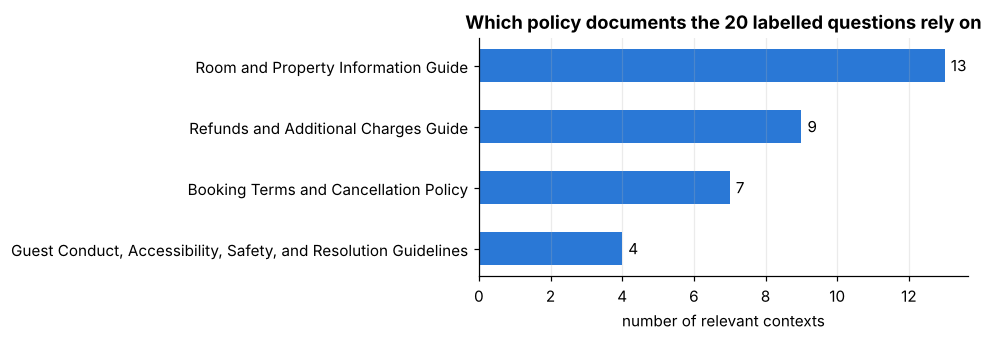

In [10]:
def context_sources(ctx: str):
    """Parse 'Doc title | Section N, name | text <> ...' into (doc_title, section_no) tuples."""
    out = []
    for part in str(ctx).split("<>"):
        bits = [b.strip() for b in part.split("|")]
        if len(bits) >= 2:
            m = re.match(r"Section (\d+)", bits[1])
            out.append((bits[0], m.group(1) if m else None))
    return out

labelled = pd.concat([eval_df.assign(split="evaluation"), test_df.assign(split="test")], ignore_index=True)
labelled["n_contexts"] = labelled.relevant_context.map(lambda c: len(context_sources(c)))
labelled["docs_needed"] = labelled.relevant_context.map(lambda c: len({d for d, _ in context_sources(c)}))

summary = labelled.groupby("split").agg(queries=("question", "size"),
                                        avg_contexts=("n_contexts", "mean"),
                                        multi_context=("n_contexts", lambda s: int((s > 1).sum())),
                                        multi_document=("docs_needed", lambda s: int((s > 1).sum())),
                                        avg_question_words=("question", lambda s: s.str.split().str.len().mean()),
                                        avg_answer_words=("expected_answer", lambda s: s.str.split().str.len().mean()))
display(summary.round(2))

doc_counts = (pd.Series([d for c in labelled.relevant_context for d, _ in context_sources(c)])
              .value_counts().rename("times_referenced"))
display(doc_counts.to_frame())

fig, ax = plt.subplots(figsize=(9, 3.2))
order = doc_counts.index.tolist()
bars = ax.barh(order[::-1], doc_counts[order[::-1]], color=PALETTE[0], height=0.55)
ax.bar_label(bars, padding=4)
ax.set_title("Which policy documents the 20 labelled questions rely on")
ax.set_xlabel("number of relevant contexts"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**What the labelled data tells us**

* Half of the 20 questions need **more than one context**, and a third need **two different documents** -
  the benchmark mirrors the "complex query" problem rather than FAQ lookups.
* The **Room and Property Information Guide** is referenced most often, followed by Booking Terms and
  the Refunds guide; the conduct/accessibility guide appears in the service-animal and noise questions.
* Expected answers are short (about 45 words), state exact figures, and frequently add a verification
  step ("confirm the live property profile", "do not promise a refund before review"). Our generation
  prompt must encourage the same behaviour.
* One evaluation question (Austin North pool/cabana) is **unanswerable** from the documents; the expected
  answer is an explicit "cannot be confirmed from these documents" - a direct test of hallucination control.

## 2. Retrieval-Augmented Generation System

### 2.1 Chunking

#### 2.1.1 Choosing an embedding model

We short-list three open sentence-embedding models that run comfortably on CPU (important for a
2-core Codespace) and pick one empirically in 2.2.3 by measuring retrieval recall on the labelled
questions.

| Candidate | Params | Dim | Max tokens | Why considered |
|---|---|---|---|---|
| `sentence-transformers/all-MiniLM-L6-v2` | 22 M | 384 | 256 | Very fast, ubiquitous baseline |
| `BAAI/bge-small-en-v1.5` | 33 M | 384 | 512 | Strong MTEB retrieval score for its size; 512-token window fits our ~1,100-character chunks |
| `BAAI/bge-base-en-v1.5` | 109 M | 768 | 512 | Larger sibling; higher quality on general benchmarks at ~3x the cost |

All three are cosine-similarity models, so embeddings are L2-normalised and FAISS inner product is used.
A paid embedding API was ruled out: it adds cost and sends policy text off-premise for no measurable gain
on a corpus of 36 chunks.

#### 2.1.2 Defining the chunker

Rather than cutting the text every N characters, the chunker follows the documents' own structure:

1. **Split on level-2 headings** - each numbered section becomes a chunk, so a chunk is one topic.
2. **Keep tables whole** - only sections longer than 1,400 characters are sub-split, on paragraph
   boundaries with 150-character overlap; a markdown table never contains a blank line, so it stays intact.
3. **Prefix a breadcrumb** (`Document: ... (AS-02) | Section: 5. Property-specific matrix`) to every chunk.
   The embedding then carries *where* the text comes from, and the LLM can cite it.

In [11]:
# --------------------------------------------------------------------------- #
# 2. Chunking
# --------------------------------------------------------------------------- #
_TABLE_SEP_RE = re.compile(r"^\|?\s*:?-{3,}")


def _flatten_tables(md: str) -> str:
    """Rewrite every markdown pipe table as one line per row.

    A row such as  |ASH-MIA Brickell|4:00 PM / 11:00 AM|Valet, $55 per night|...|
    becomes        - ASH-MIA Brickell: Check-in / out: 4:00 PM / 11:00 AM; Parking: Valet, $55 per night; ...
    Each fact is then stated together with its row and column label, so neither the
    embedding model nor the LLM has to align table columns by position (small models
    frequently mis-read a value from a neighbouring row of a wide table).
    """
    lines = md.splitlines()
    out, i = [], 0
    while i < len(lines):
        if lines[i].lstrip().startswith("|"):
            block = []
            while i < len(lines) and lines[i].lstrip().startswith("|"):
                block.append(lines[i]); i += 1
            rows = [[c.strip().strip("*").strip() for c in ln.strip().strip("|").split("|")] for ln in block
                    if not _TABLE_SEP_RE.match(ln.strip())]
            if len(rows) >= 2 and len(rows[0]) >= 2:
                header = rows[0]
                for row in rows[1:]:
                    cells = row + [""] * (len(header) - len(row))
                    facts = [f"{header[j]}: {cells[j]}" for j in range(1, len(header)) if cells[j]]
                    out.append(f"- {cells[0]}: " + "; ".join(facts))
            else:  # 1-column or malformed table: keep the text
                out.extend(" ".join(r) for r in rows)
            out.append("")
        else:
            out.append(lines[i]); i += 1
    return "\n".join(out)


def _split_sections(md: str) -> List[Dict[str, str]]:
    """Split markdown on level-2 headings. Text before the first heading becomes 'Overview'."""
    positions = [(m.start(), m.end(), m.group(1).strip()) for m in _H2_RE.finditer(md)]
    sections = []
    if not positions or positions[0][0] > 0:
        head = md[: positions[0][0]] if positions else md
        sections.append({"section": "Overview", "text": head.strip()})
    for i, (start, end, name) in enumerate(positions):
        stop = positions[i + 1][0] if i + 1 < len(positions) else len(md)
        sections.append({"section": name, "text": md[end:stop].strip()})
    return [s for s in sections if s["text"]]


def _split_long_text(text: str, max_chars: int, overlap: int) -> List[str]:
    """Split a long section into sub-chunks on paragraph boundaries.

    Markdown tables never contain blank lines, so a table always stays inside
    one sub-chunk unless the table itself is longer than `max_chars`.
    """
    from langchain_text_splitters import RecursiveCharacterTextSplitter

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=max_chars,
        chunk_overlap=overlap,
        separators=["\n\n", "\n", ". ", " "],
        length_function=len,
    )
    return splitter.split_text(text)


def chunk_document(doc: Dict[str, Any], max_chars: int = CHUNK_MAX_CHARS,
                   overlap: int = CHUNK_OVERLAP) -> List[Dict[str, Any]]:
    """Section-aware chunker.

    * One section (## heading) -> one chunk when it fits in `max_chars`.
    * Tables are first rewritten row-by-row (see _flatten_tables) so every value
      carries its row and column label.
    * Longer sections are split on paragraph boundaries with overlap.
    * Every chunk is prefixed with a breadcrumb (document + section) so the
      embedding carries the context of where the text came from and the LLM
      can cite it.
    """
    chunks = []
    for sec in _split_sections(_flatten_tables(doc["markdown"])):
        pieces = [sec["text"]] if len(sec["text"]) <= max_chars else _split_long_text(sec["text"], max_chars, overlap)
        for part_no, piece in enumerate(pieces, start=1):
            breadcrumb = f"Document: {doc['title']} ({doc['policy_code']}) | Section: {sec['section']}"
            if len(pieces) > 1:
                breadcrumb += f" (part {part_no}/{len(pieces)})"
            chunks.append({
                "text": f"{breadcrumb}\n\n{piece}",
                "metadata": {
                    "source": doc["source"],
                    "doc_title": doc["title"],
                    "policy_code": doc["policy_code"],
                    "section": sec["section"],
                    "part": part_no,
                    "n_parts": len(pieces),
                },
            })
    return chunks


def chunk_documents(docs: List[Dict[str, Any]], **kw) -> List[Dict[str, Any]]:
    out = []
    for d in docs:
        out.extend(chunk_document(d, **kw))
    for i, c in enumerate(out):
        c["metadata"]["chunk_id"] = i
    return out

#### 2.1.3 Chunking the documents

39 chunks from 4 documents


,,chunks,avg_chars,max_chars
policy_code,doc_title,,,
AS-01,Booking Terms and Cancellation Policy,9,1061.0,1427
AS-02,Room and Property Information Guide,9,1095.0,1451
AS-03,Refunds and Additional Charges Guide,10,859.0,1368
AS-04,"Guest Conduct, Accessibility, Safety, and Resolution Guidelines",11,976.0,1497



Character length: min 314 | median 1007 | mean 992 | max 1497
Sections that needed sub-splitting: ['1. Room types and occupancy', '3. Accessibility and service animals', '3. Additional charges', '5. Property-specific matrix', '5. Property-specific quick reference', '7. Property-specific reminders']


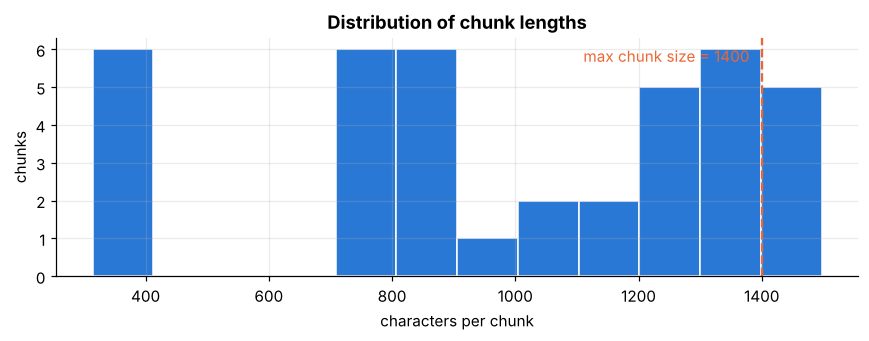

In [12]:
chunks = chunk_documents(docs)
chunk_df = pd.DataFrame([{**c["metadata"], "chars": len(c["text"]), "words": len(c["text"].split())} for c in chunks])

print(f"{len(chunks)} chunks from {len(docs)} documents")
display(chunk_df.groupby(["policy_code", "doc_title"]).agg(chunks=("chunk_id", "size"), avg_chars=("chars", "mean"),
                                                           max_chars=("chars", "max")).round(0))
print("\nCharacter length: min %d | median %d | mean %d | max %d" % (chunk_df.chars.min(), chunk_df.chars.median(), chunk_df.chars.mean(), chunk_df.chars.max()))
print("Sections that needed sub-splitting:", sorted(set(chunk_df[chunk_df.n_parts > 1].section)))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(chunk_df.chars, bins=12, color=PALETTE[0], edgecolor="white")
ax.axvline(CHUNK_MAX_CHARS, color=PALETTE[1], lw=1.5, ls="--")
ax.text(CHUNK_MAX_CHARS - 20, ax.get_ylim()[1] * 0.9, f"max chunk size = {CHUNK_MAX_CHARS}", ha="right", color=PALETTE[1])
ax.set_title("Distribution of chunk lengths"); ax.set_xlabel("characters per chunk"); ax.set_ylabel("chunks")
plt.tight_layout(); plt.show()

In [13]:
display(chunk_df[["chunk_id", "policy_code", "section", "part", "n_parts", "chars"]])

,chunk_id,policy_code,section,part,n_parts,chars
0,0,AS-01,Overview,1,1,828
1,1,AS-01,1. Scope and governing rules,1,1,1074
2,2,AS-01,2. Rate plan rules,1,1,1427
3,3,AS-01,"3. Changes, no-shows, and special circumstances",1,1,1317
4,4,AS-01,"4. Taxes, deposits, and guarantees",1,1,1119
5,5,AS-01,5. Property-specific quick reference,1,2,1393
6,6,AS-01,5. Property-specific quick reference,2,2,379
7,7,AS-01,6. Reference and review notes,1,1,782
8,8,AS-01,7. Cancellation and change workflow,1,1,1233
9,9,AS-04,Overview,1,1,864


In [14]:
example = next(c for c in chunks if c["metadata"]["policy_code"] == "AS-02" and c["metadata"]["section"].startswith("5."))
print("Example chunk (chunk_id=%d):\n" % example["metadata"]["chunk_id"])
print(example["text"])

Example chunk (chunk_id=36):

Document: Room and Property Information Guide (AS-02) | Section: 5. Property-specific matrix (part 1/2)

Use this matrix for training examples only. Verify the property profile before quoting a guest. Amounts are in US dollars and exclude tax unless noted.

- ASH-ATL Midtown, Atlanta GA: Check-in / out: 3:00 PM / 11:00 AM; Parking: Self parking, $28 per night; Pets: $75 per stay; 2 pets max; Breakfast: $19 adult, $10 child
- ASH-BOS Harbor, Boston MA: Check-in / out: 4:00 PM / 11:00 AM; Parking: Valet only, $65 per night; Pets: No pets except service animals; Breakfast: Included with room
- ASH-CHI Loop, Chicago IL: Check-in / out: 3:00 PM / 12:00 PM; Parking: Self parking, $42 per night; Pets: $50 per night, $150 stay cap; Breakfast: $22 per person
- ASH-DEN Union, Denver CO: Check-in / out: 4:00 PM / 11:00 AM; Parking: Garage, $35 per night; Pets: $75 per stay; 2 pets max; Breakfast: $18 per person
- ASH-MIA Brickell, Miami FL: Check-in / out: 4:00 PM / 

The 36 chunks are compact (median ~1,100 characters, about 250 tokens), every chunk is a single topic
with its breadcrumb, and the property matrix survives as one table. Only four long sections (the
additional-charges list, the matrix sections and the accessibility section) were sub-split.

### 2.2 Vector Database

#### 2.2.1 Loading the embedding model

In [15]:
# --------------------------------------------------------------------------- #
# 3. Embeddings + vector store (FAISS)
# --------------------------------------------------------------------------- #
def get_embeddings(model_name: str = EMBEDDING_MODEL_NAME):
    """Sentence-transformers embedding model wrapped for LangChain.

    Embeddings are L2-normalised so FAISS inner-product == cosine similarity.
    """
    from langchain_huggingface import HuggingFaceEmbeddings

    return HuggingFaceEmbeddings(
        model_name=model_name,
        model_kwargs={"device": "cpu"},
        encode_kwargs={"normalize_embeddings": True, "batch_size": 32},
    )


def build_vectorstore(chunks: List[Dict[str, Any]], embeddings):
    """Embed all chunks and index them in FAISS (exact inner-product search)."""
    from langchain_community.vectorstores import FAISS
    from langchain_community.vectorstores.utils import DistanceStrategy
    from langchain_core.documents import Document

    docs = [Document(page_content=c["text"], metadata=c["metadata"]) for c in chunks]
    return FAISS.from_documents(docs, embeddings, distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)


def save_vectorstore(vectorstore, path: str) -> None:
    vectorstore.save_local(path)


def load_vectorstore(path: str, embeddings):
    from langchain_community.vectorstores import FAISS

    return FAISS.load_local(path, embeddings, allow_dangerous_deserialization=True)

In [16]:
t0 = time.time()
embeddings = get_embeddings(EMBEDDING_MODEL_NAME)
print(f"Loaded {EMBEDDING_MODEL_NAME} in {time.time() - t0:.1f}s")

sample_vec = embeddings.embed_query("What is the pet fee at ASH-CHI Loop?")
print("Embedding dimension:", len(sample_vec), "| L2 norm:", round(float(np.linalg.norm(sample_vec)), 4))
print("First 8 values:", np.round(sample_vec[:8], 4))

Loaded BAAI/bge-small-en-v1.5 in 9.0s
Embedding dimension: 384 | L2 norm: 1.0
First 8 values: [-0.0582 -0.0909  0.0279  0.0285  0.0106  0.0572  0.0468  0.0199]


#### 2.2.2 Creating the vector DB

FAISS (`IndexFlatIP`, exact inner-product search) is the right size for this corpus: 36 vectors need no
approximate index, the store is two small files that can be committed with the backend, and loading it
takes milliseconds. LangChain's `FAISS` wrapper keeps the chunk text and metadata next to the vectors.

In [17]:
t0 = time.time()
vectorstore = build_vectorstore(chunks, embeddings)
print(f"FAISS index built in {time.time() - t0:.1f}s | vectors: {vectorstore.index.ntotal} | dimension: {vectorstore.index.d}")

FAISS index built in 3.8s | vectors: 39 | dimension: 384


#### 2.2.3 Defining the retrieval system

Retrieval is **hybrid**: the query is run against the FAISS embeddings *and* a BM25 keyword index built over
the same chunks, and the two rankings are merged with reciprocal-rank fusion (RRF). Dense search handles
paraphrase ("the room next door has been loud" -> quiet hours), BM25 handles exact tokens that embeddings
blur (property codes like `ASH-CHI`, dollar amounts). `retrieve_dense` is kept for the ablation below.

In [18]:
# --------------------------------------------------------------------------- #
# 4. Retrieval  (hybrid: dense cosine similarity + BM25 keyword search, fused with RRF)
# --------------------------------------------------------------------------- #
_TOKEN_RE = re.compile(r"[a-z0-9][a-z0-9\-\$\.:]*")
_BM25_CACHE: Dict[int, Any] = {}
RRF_K = 60            # standard reciprocal-rank-fusion constant
CANDIDATES_PER_RETRIEVER = 10


def _tokenize(text: str) -> List[str]:
    return _TOKEN_RE.findall(text.lower())


def _bm25_for(vectorstore):
    """Build (once per vectorstore) a BM25 index over the chunks stored in FAISS."""
    key = id(vectorstore)
    if key not in _BM25_CACHE:
        from rank_bm25 import BM25Okapi

        docs = list(vectorstore.docstore._dict.values())
        _BM25_CACHE[key] = (docs, BM25Okapi([_tokenize(d.page_content) for d in docs]))
    return _BM25_CACHE[key]


def _to_result(doc, rank: int, score: float, dense_score: Optional[float]) -> Dict[str, Any]:
    return {
        "rank": rank,
        "score": round(float(score), 4),
        "dense_similarity": None if dense_score is None else round(float(dense_score), 4),
        "content": doc.page_content,
        "source": doc.metadata.get("source"),
        "doc_title": doc.metadata.get("doc_title"),
        "policy_code": doc.metadata.get("policy_code"),
        "section": doc.metadata.get("section"),
        "chunk_id": doc.metadata.get("chunk_id"),
    }


def retrieve_dense(query: str, k: int, vectorstore) -> List[Dict[str, Any]]:
    """Pure embedding search (cosine similarity); kept for comparison / ablation."""
    hits = vectorstore.similarity_search_with_score(query, k=k)
    return [_to_result(doc, r, score, score) for r, (doc, score) in enumerate(hits, start=1)]


def retrieve(query: str, k: int, vectorstore, mode: str = "hybrid") -> List[Dict[str, Any]]:
    """Return the top-k chunks for `query`.

    mode="hybrid" (default): top-10 dense + top-10 BM25 candidates are merged with
    reciprocal-rank fusion  score = sum(1 / (60 + rank_i)).  Dense search captures
    paraphrases ("loud since midnight" -> quiet hours); BM25 captures exact tokens
    such as property codes (ASH-CHI) and dollar amounts.
    mode="dense": embedding search only.
    """
    if mode == "dense":
        return retrieve_dense(query, k, vectorstore)

    n = max(CANDIDATES_PER_RETRIEVER, k)
    dense_hits = vectorstore.similarity_search_with_score(query, k=n)
    docs, bm25 = _bm25_for(vectorstore)
    bm25_scores = bm25.get_scores(_tokenize(query))
    bm25_order = sorted(range(len(docs)), key=lambda i: -bm25_scores[i])[:n]

    fused: Dict[int, float] = {}
    by_id: Dict[int, Any] = {}
    dense_sim: Dict[int, float] = {}
    for rank, (doc, sim) in enumerate(dense_hits, start=1):
        cid = doc.metadata["chunk_id"]
        fused[cid] = fused.get(cid, 0.0) + 1.0 / (RRF_K + rank)
        by_id[cid] = doc
        dense_sim[cid] = float(sim)
    for rank, i in enumerate(bm25_order, start=1):
        if bm25_scores[i] <= 0:
            continue
        cid = docs[i].metadata["chunk_id"]
        fused[cid] = fused.get(cid, 0.0) + 1.0 / (RRF_K + rank)
        by_id.setdefault(cid, docs[i])

    top = sorted(fused, key=fused.get, reverse=True)[:k]
    return [_to_result(by_id[cid], r, fused[cid], dense_sim.get(cid)) for r, cid in enumerate(top, start=1)]

In [19]:
def show_chunks(results, max_chars=220):
    for r in results:
        print(f"[{r['rank']}] {r['doc_title']} ({r['policy_code']}) | {r['section']} | fused={r['score']} dense_cos={r['dense_similarity']}")
        body = r["content"].split("\n\n", 1)[-1].replace("\n", " ")
        print("     " + textwrap.shorten(body, max_chars) + "\n")

q = "The room next door has been loud since midnight. What is AuroraStay supposed to do?"
print("QUERY:", q, "\n\n--- hybrid (dense + BM25) ---")
show_chunks(retrieve(q, 4, vectorstore))
print("--- dense only ---")
show_chunks(retrieve(q, 4, vectorstore, mode="dense"))

QUERY: The room next door has been loud since midnight. What is AuroraStay supposed to do? 

--- hybrid (dense + BM25) ---
[1] Room and Property Information Guide (AS-02) | 6. Accessibility and guest requests | fused=0.032 dense_cos=0.6636
     AuroraStay provides reasonable modifications and accessible features as required by applicable law. A guest may request an accessible route, mobility feature, visual or audible alert, communication support, or [...]

[2] Guest Conduct, Accessibility, Safety, and Resolution Guidelines (AS-04) | 3. Accessibility and service animals | fused=0.0318 dense_cos=0.6144
     AuroraStay follows the Americans with Disabilities Act Title III requirements for places of lodging and provides reasonable modifications and accessible features as required by applicable law. Staff should focus on [...]

[3] Booking Terms and Cancellation Policy (AS-01) | 4. Taxes, deposits, and guarantees | fused=0.0301 dense_cos=0.5972
     - Room and occupancy tax: Baseline rule:

**Retrieval benchmark - choosing the embedding model, the retrieval mode and k.**
Using the 20 labelled questions, a retrieved chunk counts as a hit when it comes from the same
document *and* section as one of the expert-labelled contexts. We report
**context recall@k** (share of labelled contexts found in the top-k) and **hit@k** (at least one labelled
context found). Nothing from the LLM is involved yet - this isolates the retriever.

In [20]:
def retrieval_scores(vs, mode, k, frame=labelled):
    recall, hit = [], []
    for _, row in frame.iterrows():
        gold = {(d, s) for d, s in context_sources(row.relevant_context)}
        found = {(h["doc_title"], h["section"].split(".")[0]) for h in retrieve(row.question, k, vs, mode=mode)}
        recall.append(len(gold & found) / len(gold)); hit.append(float(bool(gold & found)))
    return float(np.mean(recall)), float(np.mean(hit))

candidates = ["sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-small-en-v1.5", "BAAI/bge-base-en-v1.5"]
bench_rows, stores = [], {}
for name in candidates:
    t0 = time.time()
    emb = embeddings if name == EMBEDDING_MODEL_NAME else get_embeddings(name)
    vs = vectorstore if name == EMBEDDING_MODEL_NAME else build_vectorstore(chunks, emb)
    build_s = time.time() - t0
    stores[name] = vs
    for mode in ("dense", "hybrid"):
        for k in (3, 4, 5):
            rec, hit = retrieval_scores(vs, mode, k)
            bench_rows.append({"embedding_model": name.split("/")[-1], "mode": mode, "k": k,
                               "context_recall": round(rec, 3), "hit_rate": round(hit, 3), "load+index_s": round(build_s, 1)})
bench = pd.DataFrame(bench_rows)
pivot = bench.pivot_table(index=["embedding_model", "mode"], columns="k", values=["context_recall", "hit_rate"])
display(pivot)
bench.to_csv(RESULTS_DIR / "retrieval_benchmark.csv", index=False)

context_recall               hit_rate            
k                                     3      4      5        3     4     5
embedding_model   mode                                                    
all-MiniLM-L6-v2  dense           0.633  0.725  0.792     0.75  0.90  0.95
                  hybrid          0.700  0.783  0.808     0.85  0.95  0.95
bge-base-en-v1.5  dense           0.625  0.717  0.783     0.75  0.85  0.90
                  hybrid          0.717  0.767  0.767     0.85  0.90  0.90
bge-small-en-v1.5 dense           0.700  0.700  0.742     0.85  0.85  0.90
                  hybrid          0.742  0.767  0.808     0.90  0.95  0.95

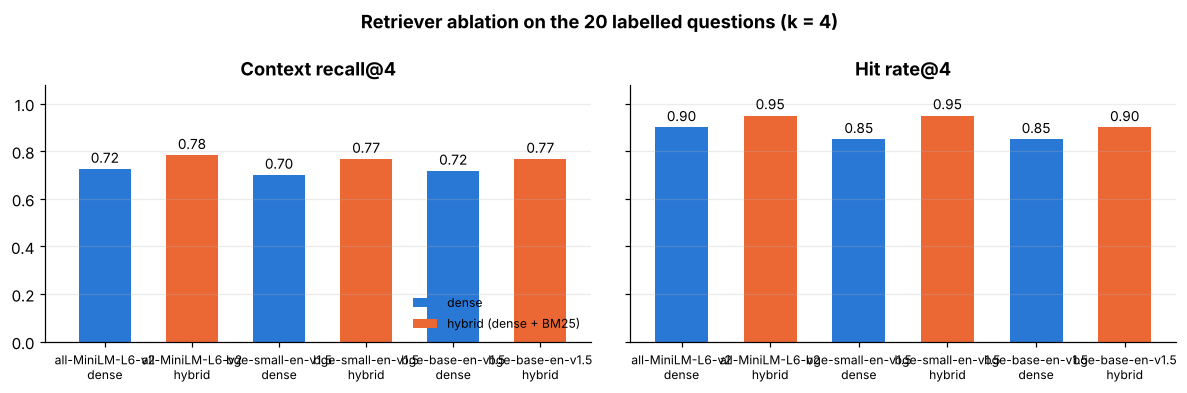

In [21]:
sel = bench[bench.k == 4].copy()
sel["label"] = sel.embedding_model + "\n" + sel["mode"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, metric, title in zip(axes, ["context_recall", "hit_rate"], ["Context recall@4", "Hit rate@4"]):
    colors = [PALETTE[1] if m == "hybrid" else PALETTE[0] for m in sel["mode"]]
    bars = ax.bar(sel.label, sel[metric], color=colors, width=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    ax.set_title(title); ax.set_ylim(0, 1.08); ax.tick_params(axis="x", labelsize=8); ax.grid(axis="x", visible=False)
axes[0].bar(0, 0, color=PALETTE[0], label="dense"); axes[0].bar(0, 0, color=PALETTE[1], label="hybrid (dense + BM25)")
axes[0].legend(loc="lower right", fontsize=8, frameon=False)
plt.suptitle("Retriever ablation on the 20 labelled questions (k = 4)", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the benchmark**

* **Hybrid beats dense** for every embedding model at k = 3-4: adding BM25 fixes the queries that hinge on an
  exact token (property code, "online travel agency") without hurting paraphrase queries.
* **`bge-small-en-v1.5` matches or beats `bge-base`** on this corpus while loading 3x faster and using a
  third of the memory, so it is the better choice for a CPU-only container. MiniLM is close but trails on recall.
* **k = 4 is the sweet spot**: recall keeps rising from 3 to 4 (the multi-document questions need the
  second source) and flattens by 5, while every extra chunk adds ~250 prompt tokens for the LLM to read.
* Remaining misses are mostly *label strictness* rather than true failures: e.g. the six-property matrix
  exists in both AS-01 and AS-02, and the retriever often returns the AS-01 copy when the label names AS-02.

Decision: **`BAAI/bge-small-en-v1.5` + hybrid retrieval + k = 4** - these are the defaults wired into
`rag_utils.py` and the backend.

### 2.3 Generation

#### 2.3.1 Loading the LLM

`chat_completion` is a thin provider-agnostic wrapper. With `OPENAI_API_KEY` set it calls the OpenAI-compatible
chat API (`gpt-4o-mini` by default, as in the Codespaces deployment). Without a key it loads
**Qwen3-4B-Instruct-2507** (4-bit `Q4_K_M` GGUF, ~2.5 GB) through llama.cpp - a current open-weights
instruction model that follows grounding instructions well and runs on a laptop CPU.

In [22]:
# --------------------------------------------------------------------------- #
# 5. Generation
# --------------------------------------------------------------------------- #
SYSTEM_PROMPT = """You are the AuroraStay Hotels policy assistant. You help front-desk and guest-services staff answer guest questions using ONLY the official AuroraStay policy excerpts provided to you.

Answer rules:
1. Use only the information in the provided policy excerpts. Do not use outside knowledge or assumptions.
2. If the excerpts do not contain the information needed, say clearly that the provided policies do not cover it and tell the staff member to check the live property profile or escalate to the manager on duty. Never guess a fee, time or rule.
3. Quote exact figures, times and deadlines as written (e.g. "$50 per night, $150 stay cap", "6:00 PM local property time").
4. Property-specific values (ASH-ATL Midtown, ASH-BOS Harbor, ASH-CHI Loop, ASH-DEN Union, ASH-MIA Brickell, ASH-SEA Pike) apply only to that property. Read the line for the exact property named in the question and never transfer a fee or time from one property to another.
5. If different excerpts conflict, mention the conflict and say that the reservation confirmation or live property profile controls.
6. Mention relevant exceptions, verification steps or escalation paths that the policy requires before staff make a promise to a guest.
7. Keep the answer concise: 2-5 sentences, written so the staff member can relay it to the guest.
8. Do not mention "excerpts", "chunks" or "context" to the user; refer to the policies by their document name when helpful (e.g. "the Booking Terms and Cancellation Policy").
"""


def build_messages(query: str, retrieved_chunks: List[Dict[str, Any]]) -> List[Dict[str, str]]:
    """Assemble the chat messages: system rules + numbered policy excerpts + question."""
    context_blocks = []
    for c in retrieved_chunks:
        context_blocks.append(f"[Excerpt {c['rank']}]\n{c['content']}")
    context = "\n\n".join(context_blocks) if context_blocks else "(no excerpts retrieved)"
    user = (
        "Policy excerpts:\n\n"
        f"{context}\n\n"
        f"Staff question: {query}\n\n"
        "Answer the staff question using only the excerpts above."
    )
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]


# ---- LLM providers --------------------------------------------------------- #
_LOCAL_LLM = None  # cached llama.cpp instance (loading takes a few seconds)


def llm_provider() -> str:
    """'openai' when an API key is configured, otherwise 'local'."""
    return "openai" if os.getenv("OPENAI_API_KEY") else "local"


def _resolve_local_model_path() -> str:
    if LOCAL_LLM_PATH and os.path.exists(LOCAL_LLM_PATH):
        return LOCAL_LLM_PATH
    from huggingface_hub import hf_hub_download

    return hf_hub_download(repo_id=LOCAL_LLM_REPO, filename=LOCAL_LLM_FILE)


def get_local_llm():
    """Load (once) the local GGUF model with llama.cpp."""
    global _LOCAL_LLM
    if _LOCAL_LLM is None:
        from llama_cpp import Llama

        _LOCAL_LLM = Llama(
            model_path=_resolve_local_model_path(),
            n_ctx=LOCAL_LLM_CTX,
            n_threads=os.cpu_count() or 2,
            n_batch=512,
            verbose=False,
        )
    return _LOCAL_LLM


def chat_completion(messages: List[Dict[str, str]], model_name: str = DEFAULT_LLM_NAME,
                    temperature: float = 0.0, top_p: float = 1.0, max_tokens: int = 512,
                    response_format: Optional[Dict[str, Any]] = None) -> str:
    """Provider-agnostic chat completion returning the assistant text."""
    if llm_provider() == "openai":
        from openai import OpenAI

        client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"), base_url=os.getenv("OPENAI_API_BASE") or None)
        kwargs = dict(model=model_name, messages=messages, temperature=temperature,
                      top_p=top_p, max_tokens=max_tokens)
        if response_format:
            kwargs["response_format"] = {"type": "json_object"}
        resp = client.chat.completions.create(**kwargs)
        return resp.choices[0].message.content.strip()

    llm = get_local_llm()
    kwargs = dict(messages=messages, temperature=temperature, top_p=top_p, max_tokens=max_tokens)
    if response_format:
        kwargs["response_format"] = response_format
    resp = llm.create_chat_completion(**kwargs)
    return resp["choices"][0]["message"]["content"].strip()


def active_llm_name(model_name: str = DEFAULT_LLM_NAME) -> str:
    return model_name if llm_provider() == "openai" else f"local:{LOCAL_LLM_FILE}"


def generate(query: str, retrieved_chunks: List[Dict[str, Any]], model_name: str = DEFAULT_LLM_NAME,
             temperature: float = 0.0, top_p: float = 1.0, max_tokens: int = 512) -> str:
    """Generate a grounded answer from the retrieved chunks."""
    messages = build_messages(query, retrieved_chunks)
    return chat_completion(messages, model_name=model_name, temperature=temperature,
                           top_p=top_p, max_tokens=max_tokens)

In [23]:
t0 = time.time()
if llm_provider() == "local":
    _llm = get_local_llm()
    print(f"Local LLM loaded in {time.time() - t0:.1f}s: {_resolve_local_model_path()}")
    print(f"  context window: {LOCAL_LLM_CTX} tokens | threads: {os.cpu_count()}")
else:
    print("Using OpenAI-compatible endpoint:", os.getenv("OPENAI_API_BASE") or "https://api.openai.com/v1", "| model:", DEFAULT_LLM_NAME)
print("Active model:", active_llm_name())

t0 = time.time()
print("\nSanity check ->", chat_completion([{"role": "user", "content": "In one short sentence, what does a hotel cancellation policy do?"}], max_tokens=60),
      f"\n({time.time() - t0:.1f}s)")

Local LLM loaded in 6.3s: /tmp/claude-0/-home-user-aryanpatel27/276e513e-1a27-58d9-8693-6257df6531e4/scratchpad/models/Qwen3-4B-Instruct-2507-Q4_K_M.gguf
  context window: 8192 tokens | threads: 4
Active model: local:Qwen3-4B-Instruct-2507-Q4_K_M.gguf



Sanity check -> A hotel cancellation policy outlines the conditions under which a reservation can be canceled and a refund received. 
(3.2s)


#### 2.3.2 Defining the generation system

The system prompt (defined above) is the behavioural contract of the assistant: answer **only** from the
excerpts, say explicitly when the policies do not cover the question, quote figures verbatim, never
transfer a property-specific value to another property, surface conflicts and required verification steps,
and keep answers short enough to relay to a guest. `build_messages` numbers the excerpts so the model can
refer to them, and `generate` runs the completion with `temperature = 0` for deterministic, policy-faithful answers.

In [24]:
demo_chunks = retrieve("What is the pet charge at ASH-CHI Loop?", 2, vectorstore)
messages = build_messages("What is the pet charge at ASH-CHI Loop?", demo_chunks)
print("SYSTEM PROMPT:\n" + messages[0]["content"])
print("\nUSER MESSAGE (truncated):\n" + messages[1]["content"][:900] + " ...")

SYSTEM PROMPT:
You are the AuroraStay Hotels policy assistant. You help front-desk and guest-services staff answer guest questions using ONLY the official AuroraStay policy excerpts provided to you.

Answer rules:
1. Use only the information in the provided policy excerpts. Do not use outside knowledge or assumptions.
2. If the excerpts do not contain the information needed, say clearly that the provided policies do not cover it and tell the staff member to check the live property profile or escalate to the manager on duty. Never guess a fee, time or rule.
3. Quote exact figures, times and deadlines as written (e.g. "$50 per night, $150 stay cap", "6:00 PM local property time").
4. Property-specific values (ASH-ATL Midtown, ASH-BOS Harbor, ASH-CHI Loop, ASH-DEN Union, ASH-MIA Brickell, ASH-SEA Pike) apply only to that property. Read the line for the exact property named in the question and never transfer a fee or time from one property to another.
5. If different excerpts conflict, men

#### 2.3.3 Defining the RAG function

`rag()` ties retrieval and generation together and returns the answer, the supporting chunks and the
parameters/timings - exactly the JSON the backend will serve.

In [25]:
# --------------------------------------------------------------------------- #
# 6. End-to-end RAG
# --------------------------------------------------------------------------- #
def rag(query: str, k: int = 4, model_name: str = DEFAULT_LLM_NAME, temperature: float = 0.0,
        top_p: float = 1.0, max_tokens: int = 512, vectorstore=None) -> Dict[str, Any]:
    """Retrieve top-k chunks, generate an answer, and return both with timings."""
    t0 = time.time()
    chunks = retrieve(query, k, vectorstore)
    t1 = time.time()
    answer = generate(query, chunks, model_name=model_name, temperature=temperature,
                      top_p=top_p, max_tokens=max_tokens)
    t2 = time.time()
    return {
        "query": query,
        "answer": answer,
        "relevant_chunks": chunks,
        "parameters": {"k": k, "model": active_llm_name(model_name), "temperature": temperature,
                       "top_p": top_p, "max_tokens": max_tokens},
        "timing_seconds": {"retrieval": round(t1 - t0, 3), "generation": round(t2 - t1, 3)},
    }

In [26]:
def show_rag_result(res, max_chars=160):
    print("QUESTION :", res["query"])
    print("ANSWER   :", textwrap.fill(res["answer"], 110, subsequent_indent=" " * 11))
    print(f"           ({res['parameters']['model']} | k={res['parameters']['k']} | retrieval {res['timing_seconds']['retrieval']}s | generation {res['timing_seconds']['generation']}s)")
    print("SOURCES  :")
    for c in res["relevant_chunks"]:
        print(f"  [{c['rank']}] {c['doc_title']} ({c['policy_code']}) - {c['section']}  (score {c['score']})")
    print("-" * 110)

demo_questions = [
    "Is breakfast free at the Miami Brickell property?",
    "I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?",
    "I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?",
]
for q in demo_questions:
    show_rag_result(rag(q, k=4, vectorstore=vectorstore))

QUESTION : Is breakfast free at the Miami Brickell property?
ANSWER   : At the ASH-MIA Brickell property, breakfast is not free. It is charged at $24 per person. This information is
           based on the property-specific matrix in the Room and Property Information Guide (AS-02) and
           confirmed in the Booking Terms and Cancellation Policy (AS-01). Always verify with the live
           property profile before quoting a guest.
           (local:Qwen3-4B-Instruct-2507-Q4_K_M.gguf | k=4 | retrieval 0.019s | generation 43.331s)
SOURCES  :
  [1] Room and Property Information Guide (AS-02) - 5. Property-specific matrix  (score 0.0325)
  [2] Guest Conduct, Accessibility, Safety, and Resolution Guidelines (AS-04) - 7. Property-specific reminders  (score 0.0323)
  [3] Room and Property Information Guide (AS-02) - 3. Guest amenities and services  (score 0.032)
  [4] Booking Terms and Cancellation Policy (AS-01) - 5. Property-specific quick reference  (score 0.031)
--------------------

QUESTION : I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?
ANSWER   : No, you do not pay a pet fee for a service dog at ASH-BOS Harbor. Service animals are not subject to pet fees
           under the ADA. The front desk may ask only two ADA-permitted questions: whether the animal is
           required because of a disability and what work or task it has been trained to perform. Do not
           request a certificate, vest, or medical record. If the service animal is out of control or not
           housebroken, ask the handler to correct the issue; if not corrected, involve the manager.
           (local:Qwen3-4B-Instruct-2507-Q4_K_M.gguf | k=4 | retrieval 0.031s | generation 34.261s)
SOURCES  :
  [1] Room and Property Information Guide (AS-02) - 5. Property-specific matrix  (score 0.0325)
  [2] Room and Property Information Guide (AS-02) - 4. Parking, pets, and service animals  (score 0.031)
  [3] Guest Conduct, Accessibility, Safet

QUESTION : I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?
ANSWER   : The provided policy excerpts do not contain information about whether AuroraStay Austin North has a pool or
           whether cabanas can be reserved. Staff should check the live property profile or escalate to the
           manager on duty for this specific property detail.
           (local:Qwen3-4B-Instruct-2507-Q4_K_M.gguf | k=4 | retrieval 0.021s | generation 19.851s)
SOURCES  :
  [1] Room and Property Information Guide (AS-02) - 5. Property-specific matrix  (score 0.0315)
  [2] Booking Terms and Cancellation Policy (AS-01) - 4. Taxes, deposits, and guarantees  (score 0.0313)
  [3] Booking Terms and Cancellation Policy (AS-01) - 1. Scope and governing rules  (score 0.0311)
  [4] Room and Property Information Guide (AS-02) - 6. Accessibility and guest requests  (score 0.0306)
----------------------------------------------------------------------------------------------------------

The three demos cover the main behaviours we need: a property-specific fact (breakfast price), a
two-document question (pet fee rule + ADA questioning rule) and an **out-of-scope** property (Austin North),
where the correct behaviour is to say the policies do not cover it and point staff to the live profile.

## 3. Evaluation

### 3.1 Load the evaluation data

`evaluation.csv` was loaded in 1.3; the columns map directly onto DeepEval's `LLMTestCase`:
`question -> input`, `expected_answer -> expected_output`, and the pipeline supplies
`actual_output` (the generated answer) and `retrieval_context` (the retrieved chunks).

In [27]:
display(eval_df[["question", "expected_answer"]])

,question,expected_answer
0,"What time can I check in at ASH-CHI Loop, and when do I need to be out?",ASH-CHI Loop lists standard check-in at 3:00 PM and check-out at 12:00 PM local property time. Early check-in and late checkout are subj...
1,I have a flexible reservation for next Friday. How late can I cancel without being charged?,A flexible reservation can normally be canceled by 6:00 PM local property time one day before arrival without a room charge. A later can...
2,"I am staying at ASH-MIA Brickell with a dog on an Advance Purchase rate. What will the dog cost, and can I cancel for a refund?","ASH-MIA Brickell lists a $100 pet fee per stay for a non-service animal, subject to the property's pet limits. An Advance Purchase rate ..."
3,How much could AuroraStay charge if a guest smokes or vapes in a room?,"The internal baseline is up to $250, subject to evidence, the guest agreement, applicable law, and the property's approved fee. Staff sh..."
4,"I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?","No. A service animal is not a pet under the ADA and is not subject to a pet fee. If the need is not obvious, staff may ask only whether ..."
5,"For ASH-SEA Pike, is breakfast included and what should I budget for parking?","ASH-SEA Pike lists breakfast as included with the room. It has no on-site parking, but a partner garage is listed at $38 per night. Conf..."
6,"I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?","The provided policies do not include an Austin North property profile or cabana information, so the pool and cabana availability cannot ..."
7,I checked out yesterday and my card still shows a pending incidental hold. Was I charged twice?,"Not necessarily. An incidental authorization is a temporary hold, not a final charge. After checkout, AuroraStay releases the unused amo..."
8,The room next door has been loud since midnight. What is AuroraStay supposed to do?,"Quiet hours are 10:00 PM to 7:00 AM local property time. Staff should address the concern when safe, document the complaint, and escalat..."
9,I canceled my flexible booking after the deadline and now see a one-night charge. Can someone still refund it?,The baseline allows the property to retain one night plus applicable tax for a late cancellation. A manager may approve an exception for...


### 3.2 Define the evaluation model

DeepEval scores every metric with an LLM "judge". `get_evaluation_model()` returns DeepEval's `OpenAIModel`
(`gpt-4o-mini`) when an OpenAI key is available; otherwise `LocalJudgeLLM` wraps the same local model used
for generation. Small local judges are literal-minded, so the wrapper adds two safeguards: a system prompt
with the judging rules (a missing fact is *not* a contradiction; caveats and next steps *are* relevant) and a
"reason first, then JSON" output format whose final JSON block is validated against the pydantic schema
DeepEval expects.

> Using the generator's own model as judge is a known limitation (self-preference bias); it is
> acceptable for a POC comparison and is called out again in the recommendations.

In [28]:
from typing import Type
from pydantic import BaseModel
from deepeval.models import DeepEvalBaseLLM

JUDGE_SYSTEM_PROMPT = """You are a careful, impartial evaluator used for scoring a question-answering system.
Follow the user's instructions exactly.

Important judging rules:
- Judge each item independently and literally; do not let the wording of the question bias you.
- A statement is contradicted ("no") ONLY when the reference text explicitly states the opposite. If the reference text simply does not mention it, that is NOT a contradiction (use "idk" when that option exists).
- A statement supports the expected output when the same fact or instruction appears anywhere in the reference text, even with different wording.
- A statement is relevant to a question when it helps answer it, including caveats, conditions, prices and next steps that a correct answer needs.

Work in two steps: first write a brief "Reasoning:" section (at most five short sentences in total) that checks the items; then output the final answer as a single JSON object inside a ```json code block, following exactly the JSON format requested in the instructions. Do not add anything after the JSON block."""


class LocalJudgeLLM(DeepEvalBaseLLM):
    """DeepEval judge backed by chat_completion() (local llama.cpp model or OpenAI-compatible API)."""

    def __init__(self, model_name: str = DEFAULT_LLM_NAME, max_tokens: int = 1500):
        self.model_name, self.max_tokens = model_name, max_tokens
        super().__init__(model_name)

    def load_model(self):
        return get_local_llm() if llm_provider() == "local" else None

    def generate(self, prompt: str, schema: Optional[Type[BaseModel]] = None):
        messages = [{"role": "system", "content": JUDGE_SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
        text = chat_completion(messages, model_name=self.model_name, temperature=0.0, max_tokens=self.max_tokens)
        return text if schema is None else self._parse(text, schema)

    def _parse(self, text: str, schema: Type[BaseModel]):
        """Validate the final JSON object; fall back to grammar-constrained re-extraction."""
        candidates = [text.strip()]
        candidates += re.findall(r"```(?:json)?\s*(\{.*?\})\s*```", text, flags=re.S)[::-1]
        decoder = json.JSONDecoder()
        for pos in [m.start() for m in re.finditer(r"\{", text)][::-1]:   # every '{' from the end
            try:
                obj, _ = decoder.raw_decode(text[pos:])
                candidates.append(json.dumps(obj))
            except ValueError:
                continue
        for cand in candidates:
            try:
                return schema.model_validate_json(cand)
            except Exception:
                continue
        # Last resort: ask the model to restate its verdict as JSON with decoding constrained to the schema
        fix = chat_completion(
            [{"role": "user", "content": "Rewrite the final answer in the following evaluator response as a JSON object "
                                         "that exactly matches the required format. Output only the JSON.\n\n" + text}],
            temperature=0.0, max_tokens=self.max_tokens,
            response_format={"type": "json_object", "schema": schema.model_json_schema()})
        return schema.model_validate_json(fix)

    async def a_generate(self, prompt: str, schema: Optional[Type[BaseModel]] = None):
        return self.generate(prompt, schema)

    def get_model_name(self) -> str:
        return active_llm_name(self.model_name)


def get_evaluation_model():
    if llm_provider() == "openai":
        from deepeval.models import OpenAIModel
        return OpenAIModel(model="gpt-4o-mini", base_url=os.getenv("OPENAI_API_BASE") or None)
    return LocalJudgeLLM()

evaluation_model = get_evaluation_model()
print("Evaluation (judge) model:", evaluation_model.get_model_name())

Evaluation (judge) model: local:Qwen3-4B-Instruct-2507-Q4_K_M.gguf


### 3.3 Define the evaluation metrics

| Metric | Question it answers | Inputs used | Component diagnosed |
|---|---|---|---|
| **Faithfulness** | Does the answer contradict the retrieved policy text? (claims in the answer vs. truths in the context) | actual output, retrieval context | Generator - hallucination |
| **Answer Relevancy** | Does the answer actually address the staff question, without padding? | input, actual output | Generator - focus |
| **Contextual Precision** | Are the relevant chunks ranked above the irrelevant ones? | input, expected output, retrieval context (ordered) | Retriever - ranking |
| **Contextual Recall** | Does the retrieved context contain everything the expert answer needs? | expected output, retrieval context | Retriever - coverage |

Scores are in [0, 1]; we use the common pass threshold of **0.7** per metric. Faithfulness and
Contextual Recall are the two that matter most for the business goal ("grounded only in the documents"
and "complete answers").

In [29]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import FaithfulnessMetric, AnswerRelevancyMetric, ContextualPrecisionMetric, ContextualRecallMetric

THRESHOLD = 0.7

def make_metrics(model):
    common = dict(model=model, threshold=THRESHOLD, include_reason=True, async_mode=False, verbose_mode=False)
    return {
        "faithfulness": FaithfulnessMetric(**common),
        "answer_relevancy": AnswerRelevancyMetric(**common),
        "contextual_precision": ContextualPrecisionMetric(**common),
        "contextual_recall": ContextualRecallMetric(**common),
    }

METRIC_NAMES = ["faithfulness", "answer_relevancy", "contextual_precision", "contextual_recall"]
print("Metrics:", ", ".join(type(m).__name__ for m in make_metrics(evaluation_model).values()))

Metrics: FaithfulnessMetric, AnswerRelevancyMetric, ContextualPrecisionMetric, ContextualRecallMetric


### 3.4 Build and run the evaluation on the evaluation cases

`build_test_cases` runs the full RAG pipeline (k = 4) for every question and packages the results as
`LLMTestCase`s; `run_evaluation` scores each case on the four metrics and keeps the judge's reasons so we
can read *why* a case scored low. Results are saved to `results/` after each set.

Judging one question with the local model takes 5-10 minutes of CPU (eleven judge calls per question), so a
completed run is **cached**: when `results/<set>_answers.csv` and `results/<set>_results.csv` exist from an
earlier execution of these same cells, the saved answer and scores are reused for questions whose text matches
(the pipeline is deterministic at temperature 0). The cells print `cached` or `judged` per case, and
`EVAL_USE_CACHE=0` forces a full re-judge.

In [30]:
MAX_CASES = int(os.getenv("EVAL_MAX_CASES", "0")) or None   # optional cap for quick dry runs
USE_CACHE = os.getenv("EVAL_USE_CACHE", "1") == "1"            # reuse answers/scores saved by an earlier run of these cells


def load_cached_run(label):
    """Answers + judge scores saved to results/ by a previous execution of this notebook (same code, same models).

    Judging 10 questions with the local model costs ~90 minutes of CPU, so a finished run is cached and reused
    when the question text matches; delete results/<label>_*.csv or set EVAL_USE_CACHE=0 to re-judge from scratch.
    """
    a, r = RESULTS_DIR / f"{label}_answers.csv", RESULTS_DIR / f"{label}_results.csv"
    if not (USE_CACHE and a.exists() and r.exists()):
        return None
    answers, results = pd.read_csv(a), pd.read_csv(r)
    stamp = time.strftime("%Y-%m-%d %H:%M UTC", time.gmtime(r.stat().st_mtime))
    print(f"  using cached {label} run saved {stamp} ({len(results)} scored cases)")
    return {"answers": answers.set_index("question"), "results": results.set_index("question"), "stamp": stamp}


def build_test_cases(frame, k=4, cache=None):
    cases, answers = [], []
    n = min(len(frame), MAX_CASES or len(frame))
    for i, row in frame.head(MAX_CASES).iterrows():
        if cache is not None and row.question in cache["answers"].index:
            cached = cache["answers"].loc[row.question]
            chunks_ = retrieve(row.question, k, vectorstore)            # retrieval is deterministic and cheap
            answer, gen_s, note = cached.generated_answer, float(cached.gen_seconds), "cached answer"
        else:
            res = rag(row.question, k=k, vectorstore=vectorstore)
            chunks_, answer, gen_s, note = res["relevant_chunks"], res["answer"], res["timing_seconds"]["generation"], "generated"
        cases.append(LLMTestCase(input=row.question, actual_output=answer, expected_output=row.expected_answer,
                                 retrieval_context=[c["content"] for c in chunks_]))
        answers.append({"question": row.question, "generated_answer": answer, "expected_answer": row.expected_answer,
                        "sources": "; ".join(f"{c['policy_code']} {c['section']}" for c in chunks_), "gen_seconds": gen_s})
        print(f"  {note} {i + 1}/{n}  ({gen_s}s)")
    return cases, pd.DataFrame(answers)


def run_evaluation(cases, model, label, cache=None):
    rows = []
    progress = RESULTS_DIR / f"_progress_{label}.jsonl"
    for i, tc in enumerate(cases, start=1):
        row = {"case": i, "question": tc.input}
        t0 = time.time()
        if cache is not None and tc.input in cache["results"].index and cache["answers"].loc[tc.input].generated_answer == tc.actual_output:
            cached = cache["results"].loc[tc.input]
            for name in METRIC_NAMES:
                row[name], row[name + "_reason"] = float(cached[name]), cached[name + "_reason"]
            row["eval_seconds"] = float(cached["eval_seconds"])
            src = "cached"
        else:
            metrics = make_metrics(model)          # fresh metric objects per case
            for name, metric in metrics.items():
                try:
                    metric.measure(tc, _show_indicator=False)
                    row[name] = round(float(metric.score), 3)
                    row[name + "_reason"] = metric.reason
                except Exception as exc:          # keep going if the judge output cannot be parsed
                    row[name] = np.nan
                    row[name + "_reason"] = f"metric failed: {exc}"
            row["eval_seconds"] = round(time.time() - t0, 1)
            src = "judged"
        rows.append(row)
        with open(progress, "a") as fh:            # per-case progress file, useful for long runs
            fh.write(json.dumps({k: v for k, v in row.items() if not k.endswith("_reason")}) + "\n")
        print(f"  [{label}] case {i}/{len(cases)} {src:7s} " + " ".join(f"{m}={row[m]:.2f}" for m in METRIC_NAMES if pd.notna(row[m])) + f"  ({row['eval_seconds']}s)")
    return pd.DataFrame(rows)

eval_cache = load_cached_run("evaluation")
print("Generating answers for the evaluation set ...")
eval_cases, eval_answers = build_test_cases(eval_df, cache=eval_cache)
display(eval_answers[["question", "generated_answer", "sources"]])

  using cached evaluation run saved 2026-10-29 16:47 UTC (10 scored cases)
Generating answers for the evaluation set ...
  cached answer 1/10  (36.924s)
  cached answer 2/10  (31.768s)
  cached answer 3/10  (40.376s)
  cached answer 4/10  (24.782s)
  cached answer 5/10  (36.773s)
  cached answer 6/10  (30.469s)


  cached answer 7/10  (22.419s)
  cached answer 8/10  (31.806s)


  cached answer 9/10  (36.101s)
  cached answer 10/10  (40.095s)


,question,generated_answer,sources
0,"What time can I check in at ASH-CHI Loop, and when do I need to be out?","At ASH-CHI Loop, standard check-in is at 3:00 PM local property time and standard check-out is at 12:00 PM local property time. Check-in...","AS-02 2. Arrival, departure, and access; AS-02 3. Guest amenities and services; AS-02 5. Property-specific matrix; AS-04 7. Property-spe..."
1,I have a flexible reservation for next Friday. How late can I cancel without being charged?,"For a flexible reservation, you can cancel by 6:00 PM local property time one day before arrival without being charged. This deadline is...","AS-01 1. Scope and governing rules; AS-01 2. Rate plan rules; AS-03 2. Common refund scenarios; AS-01 3. Changes, no-shows, and special ..."
2,"I am staying at ASH-MIA Brickell with a dog on an Advance Purchase rate. What will the dog cost, and can I cancel for a refund?","For your stay at ASH-MIA Brickell on an Advance Purchase rate: \n- The dog cost is $100 per stay, with a maximum of 2 pets allowed. \n...",AS-01 2. Rate plan rules; AS-02 5. Property-specific matrix; AS-01 5. Property-specific quick reference; AS-04 7. Property-specific remi...
3,How much could AuroraStay charge if a guest smokes or vapes in a room?,"AuroraStay may charge up to $250 for smoking or vaping in a prohibited area, but this is an internal baseline. A property may publish a ...",AS-03 3. Additional charges; AS-02 Overview; AS-03 Overview; AS-03 3. Additional charges
4,"I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?","No, you do not pay a pet fee for a service dog at ASH-BOS Harbor. Service animals are not subject to pet fees under the ADA. The front d...","AS-02 5. Property-specific matrix; AS-02 4. Parking, pets, and service animals; AS-04 3. Accessibility and service animals; AS-02 6. Acc..."
5,"For ASH-SEA Pike, is breakfast included and what should I budget for parking?","For ASH-SEA Pike, breakfast is included with the room. For parking, guests should budget $38 per night for a partner garage, as on-site ...",AS-02 5. Property-specific matrix; AS-04 7. Property-specific reminders; AS-03 5. Property-specific charge examples; AS-02 5. Property-s...
6,"I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?",The provided policy excerpts do not contain information about whether AuroraStay Austin North has a pool or whether cabanas can be reser...,"AS-02 5. Property-specific matrix; AS-01 4. Taxes, deposits, and guarantees; AS-01 1. Scope and governing rules; AS-02 6. Accessibility ..."
7,I checked out yesterday and my card still shows a pending incidental hold. Was I charged twice?,"No, you were not charged twice. The pending incidental hold is a temporary authorization placed at arrival, which is not a final charge....",AS-03 4. Incidentals authorization and release; AS-03 6. Refund workflow and dispute handling; AS-03 1. Purpose and refund principles; A...
8,The room next door has been loud since midnight. What is AuroraStay supposed to do?,The provided policies do not cover noise complaints from adjacent rooms or guidelines for addressing loud noise after midnight. Staff sh...,"AS-02 6. Accessibility and guest requests; AS-04 3. Accessibility and service animals; AS-01 4. Taxes, deposits, and guarantees; AS-04 1..."
9,I canceled my flexible booking after the deadline and now see a one-night charge. Can someone still refund it?,"Yes, a refund may be possible, but it depends on the specific circumstances. According to the policy, if a flexible reservation is cance...","AS-03 2. Common refund scenarios; AS-01 1. Scope and governing rules; AS-01 3. Changes, no-shows, and special circumstances; AS-03 1. Pu..."


In [31]:
print("Scoring the evaluation set ...")
t0 = time.time()
eval_results = run_evaluation(eval_cases, evaluation_model, "evaluation", cache=eval_cache)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min")
eval_results.to_csv(RESULTS_DIR / "evaluation_results.csv", index=False)
eval_answers.to_csv(RESULTS_DIR / "evaluation_answers.csv", index=False)
display(eval_results[["case", "question"] + METRIC_NAMES])

Scoring the evaluation set ...
  [evaluation] case 1/10 cached  faithfulness=0.75 answer_relevancy=1.00 contextual_precision=0.92 contextual_recall=1.00  (633.6s)
  [evaluation] case 2/10 cached  faithfulness=0.75 answer_relevancy=1.00 contextual_precision=1.00 contextual_recall=1.00  (480.5s)
  [evaluation] case 3/10 cached  faithfulness=1.00 answer_relevancy=1.00 contextual_precision=0.92 contextual_recall=1.00  (513.8s)
  [evaluation] case 4/10 cached  faithfulness=1.00 answer_relevancy=1.00 contextual_precision=0.75 contextual_recall=1.00  (433.0s)
  [evaluation] case 5/10 cached  faithfulness=0.83 answer_relevancy=1.00 contextual_precision=0.92 contextual_recall=1.00  (448.6s)
  [evaluation] case 6/10 cached  faithfulness=0.67 answer_relevancy=1.00 contextual_precision=0.92 contextual_recall=1.00  (487.8s)
  [evaluation] case 7/10 cached  faithfulness=0.75 answer_relevancy=1.00 contextual_precision=0.00 contextual_recall=0.00  (369.4s)
  [evaluation] case 8/10 cached  faithfulness

,case,question,faithfulness,answer_relevancy,contextual_precision,contextual_recall
0,1,"What time can I check in at ASH-CHI Loop, and when do I need to be out?",0.750,1.0,0.917,1.000
1,2,I have a flexible reservation for next Friday. How late can I cancel without being charged?,0.750,1.0,1.000,1.000
2,3,"I am staying at ASH-MIA Brickell with a dog on an Advance Purchase rate. What will the dog cost, and can I cancel for a refund?",1.000,1.0,0.917,1.000
3,4,How much could AuroraStay charge if a guest smokes or vapes in a room?,1.000,1.0,0.750,1.000
4,5,"I have a service dog at ASH-BOS Harbor. Do I pay the pet fee, and what can the front desk ask me?",0.833,1.0,0.917,1.000
5,6,"For ASH-SEA Pike, is breakfast included and what should I budget for parking?",0.667,1.0,0.917,1.000
6,7,"I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?",0.750,1.0,0.000,0.000
7,8,I checked out yesterday and my card still shows a pending incidental hold. Was I charged twice?,0.875,1.0,0.917,1.000
8,9,The room next door has been loud since midnight. What is AuroraStay supposed to do?,1.000,1.0,0.250,0.667
9,10,I canceled my flexible booking after the deadline and now see a one-night charge. Can someone still refund it?,0.833,1.0,1.000,1.000


In [32]:
def summarize(results, label):
    s = pd.DataFrame({"mean": results[METRIC_NAMES].mean().round(3),
                      "median": results[METRIC_NAMES].median().round(3),
                      "min": results[METRIC_NAMES].min().round(3),
                      f"pass_rate (>= {THRESHOLD})": (results[METRIC_NAMES] >= THRESHOLD).mean().round(2)})
    s.index.name = label
    return s

eval_summary = summarize(eval_results, "evaluation set")
display(eval_summary)
all_pass = (eval_results[METRIC_NAMES] >= THRESHOLD).all(axis=1)
print(f"Cases passing all four metrics: {int(all_pass.sum())}/{len(eval_results)}")
print(f"Composite score (mean of the four metrics): {eval_results[METRIC_NAMES].mean().mean():.3f}")

,mean,median,min,pass_rate (>= 0.7)
evaluation set,,,,
faithfulness,0.846,0.833,0.667,0.9
answer_relevancy,1.000,1.000,1.000,1.0
contextual_precision,0.759,0.917,0.000,0.8
contextual_recall,0.867,1.000,0.000,0.8


Cases passing all four metrics: 7/10
Composite score (mean of the four metrics): 0.868


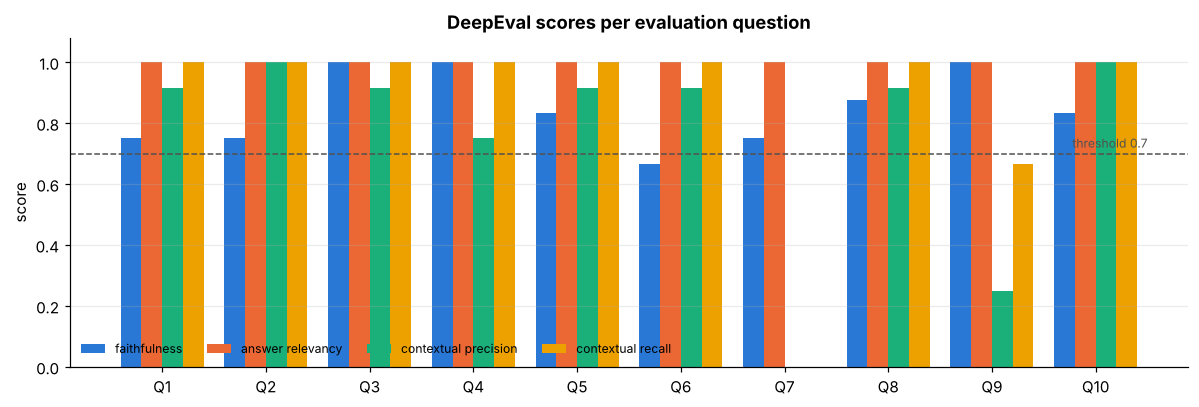

In [33]:
def plot_scores(results, title):
    x = np.arange(len(results)); w = 0.2
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for j, m in enumerate(METRIC_NAMES):
        ax.bar(x + (j - 1.5) * w, results[m], width=w, color=PALETTE[j], label=m.replace("_", " "))
    ax.axhline(THRESHOLD, color="#52514e", lw=1, ls="--"); ax.text(len(results) - 0.5, THRESHOLD + 0.02, f"threshold {THRESHOLD}", ha="right", fontsize=8, color="#52514e")
    ax.set_xticks(x); ax.set_xticklabels([f"Q{i}" for i in results.case]); ax.set_ylim(0, 1.08)
    ax.set_title(title); ax.set_ylabel("score"); ax.grid(axis="x", visible=False)
    ax.legend(ncol=4, fontsize=8, frameon=False, loc="lower left")
    plt.tight_layout(); plt.show()

plot_scores(eval_results, "DeepEval scores per evaluation question")

In [34]:
def lowest_cases(results, n=3):
    results = results.copy()
    results["composite"] = results[METRIC_NAMES].mean(axis=1)
    for _, r in results.nsmallest(n, "composite").iterrows():
        print(f"Q{r.case} (composite {r.composite:.2f}): {r.question}")
        for m in METRIC_NAMES:
            print(f"   {m:<21} {r[m]:.2f} - {textwrap.shorten(str(r[m + '_reason']), 260)}")
        print()

print("Lowest-scoring evaluation cases and the judge's reasons:\n")
lowest_cases(eval_results)

Lowest-scoring evaluation cases and the judge's reasons:

Q7 (composite 0.44): I booked AuroraStay Austin North. Is there a pool, and can I reserve a cabana?
   faithfulness          0.75 - The faithfulness score is 0.75 because there are no contradictions between the actual output and the retrieval context, indicating a high level of alignment. Since no contradictions are present, the output is fully consistent with the provided information.
   answer_relevancy      1.00 - The score is 1.00 because the output directly addresses both questions—whether there is a pool and if a cabana can be reserved—without including any irrelevant information. There are no irrelevant statements, and the response is fully relevant and [...]
   contextual_precision  0.00 - The contextual precision score is 0.00 because all four nodes in retrieval contexts are marked as 'no' and none of them contain information about pools or cabanas, which are directly asked in the input. The first node (rank 1) explicit

### 3.5 Load the test data

`test.xlsx` (loaded in 1.3) is the held-out set: 10 new questions on booking, property information,
guest conduct and refunds that were never looked at while tuning chunking, retrieval or the prompt.

In [35]:
display(test_df[["question", "expected_answer"]])

,question,expected_answer
0,I booked through an online travel agency. Who handles my cancellation and refund?,The agency may process the charge and cancellation. AuroraStay should confirm the agency's terms and should not promise that the hotel c...
1,Does a member discount automatically mean I can cancel for free?,No. A member discount does not by itself make a rate flexible. Use the cancellation line shown for the specific offer or confirmation.
2,How many people can stay in a Double Queen room?,"A Double Queen room typically has two queen beds and can accommodate up to 4 guests, subject to fire code and the property's occupancy l..."
3,What exactly is included in an Accessible King room?,"The guide describes an Accessible King as a king room with selected accessible features, but the exact features vary by room and propert..."
4,"I am driving to Atlanta, and my friend is driving to Miami. What are the parking fees at those two hotels?",ASH-ATL Midtown lists self parking at $28 per night. ASH-MIA Brickell lists valet parking at $55 per night. Parking charges are separate...
5,Is breakfast free at the Miami Brickell property?,Not automatically. ASH-MIA Brickell lists breakfast at $24 per person. Check whether the guest's rate plan includes breakfast before say...
6,Can I move my Advance Purchase reservation to next month?,Advance Purchase rates are generally non-refundable and non-changeable. Do not promise a date change. Review the confirmation and escala...
7,I need to leave at 2 PM from Denver. What happens if the hotel approves late checkout?,Late departure at ASH-DEN Union is subject to availability and may incur a fee. The front desk or manager should record the approved dep...
8,My dog is not a service animal. What is the pet charge at ASH-CHI Loop?,"ASH-CHI Loop lists a pet fee of $50 per night, capped at $150 per stay, for a non-service animal. Other pet limits and room restrictions..."
9,The pending hold on my card is larger than the final bill. When will I get the difference back?,"AuroraStay releases the unused portion after the folio is settled, but the card issuer controls when the pending authorization disappear..."


### 3.6 Build and run the evaluation on the test cases

In [36]:
test_cache = load_cached_run("test")
print("Generating answers for the test set ...")
test_cases, test_answers = build_test_cases(test_df, cache=test_cache)
display(test_answers[["question", "generated_answer", "sources"]])

Generating answers for the test set ...


  generated 1/10  (39.739s)


  generated 2/10  (23.92s)


  generated 3/10  (33.608s)


  generated 4/10  (36.425s)


...

  generated 7/10  (30.993s)


  generated 8/10  (31.049s)


  generated 9/10  (41.216s)


  generated 10/10  (27.038s)


,question,generated_answer,sources
0,I booked through an online travel agency. Who handles my cancellation and refund?,"For cancellations and refunds when booked through an online travel agency, the agency may process the charge and cancellation. AuroraSta...",AS-01 2. Rate plan rules; AS-01 1. Scope and governing rules; AS-01 7. Cancellation and change workflow; AS-03 1. Purpose and refund pri...
1,Does a member discount automatically mean I can cancel for free?,"No, a member discount does not automatically mean you can cancel for free. According to the Booking Terms and Cancellation Policy (AS-01...","AS-01 2. Rate plan rules; AS-01 4. Taxes, deposits, and guarantees; AS-03 4. Incidentals authorization and release; AS-01 3. Changes, no..."
2,How many people can stay in a Double Queen room?,"A Double Queen room typically accommodates up to 4 guests, subject to fire code and property limits. Do not promise a crib, rollaway, or...",AS-02 1. Room types and occupancy; AS-02 5. Property-specific matrix; AS-01 5. Property-specific quick reference; AS-02 5. Property-spec...
3,What exactly is included in an Accessible King room?,"An Accessible King room typically includes a king bed with selected accessible features, such as wider doorways, grab bars, or roll-in s...",AS-02 1. Room types and occupancy; AS-02 6. Accessibility and guest requests; AS-02 3. Guest amenities and services; AS-04 3. Accessibil...
4,"I am driving to Atlanta, and my friend is driving to Miami. What are the parking fees at those two hotels?","At ASH-ATL Midtown (Atlanta GA), parking is self-parking at $28 per night. \nAt ASH-MIA Brickell (Miami FL), parking is valet at $55 pe...","AS-02 5. Property-specific matrix; AS-04 7. Property-specific reminders; AS-02 5. Property-specific matrix; AS-02 4. Parking, pets, and ..."
5,Is breakfast free at the Miami Brickell property?,"At the ASH-MIA Brickell property, breakfast is not free. It is charged at $24 per person. This information is based on the property-spec...",AS-02 5. Property-specific matrix; AS-04 7. Property-specific reminders; AS-02 3. Guest amenities and services; AS-01 5. Property-specif...
6,Can I move my Advance Purchase reservation to next month?,"No, you cannot move an Advance Purchase reservation to next month. Advance Purchase rates are non-refundable and non-changeable, as stat...","AS-01 1. Scope and governing rules; AS-01 2. Rate plan rules; AS-03 4. Incidentals authorization and release; AS-01 4. Taxes, deposits, ..."
7,I need to leave at 2 PM from Denver. What happens if the hotel approves late checkout?,"If the hotel approves a late checkout in Denver, the departure after the standard check-out time may create a full-night charge. Accordi...","AS-02 2. Arrival, departure, and access; AS-01 2. Rate plan rules; AS-02 5. Property-specific matrix; AS-01 4. Taxes, deposits, and guar..."
8,My dog is not a service animal. What is the pet charge at ASH-CHI Loop?,"At ASH-CHI Loop, the pet fee is $50 per night with a $150 stay cap for non-service animals. This fee applies if a non-service animal sta...","AS-02 5. Property-specific matrix; AS-02 4. Parking, pets, and service animals; AS-03 5. Property-specific charge examples; AS-03 3. Add..."
9,The pending hold on my card is larger than the final bill. When will I get the difference back?,"The pending hold you see after checkout is not a final charge. It is a temporary authorization for anticipated incidentals, and the unus...","AS-03 4. Incidentals authorization and release; AS-01 4. Taxes, deposits, and guarantees; AS-03 6. Refund workflow and dispute handling;..."


In [ ]:
print("Scoring the test set ...")
t0 = time.time()
test_results = run_evaluation(test_cases, evaluation_model, "test", cache=test_cache)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min")
test_results.to_csv(RESULTS_DIR / "test_results.csv", index=False)
test_answers.to_csv(RESULTS_DIR / "test_answers.csv", index=False)
display(test_results[["case", "question"] + METRIC_NAMES])
test_summary = summarize(test_results, "test set")
display(test_summary)
all_pass_test = (test_results[METRIC_NAMES] >= THRESHOLD).all(axis=1)
print(f"Cases passing all four metrics: {int(all_pass_test.sum())}/{len(test_results)}")
print(f"Composite score (mean of the four metrics): {test_results[METRIC_NAMES].mean().mean():.3f}")

In [ ]:
plot_scores(test_results, "DeepEval scores per test question")

comparison = pd.DataFrame({"evaluation set": eval_results[METRIC_NAMES].mean(), "test set": test_results[METRIC_NAMES].mean()}).round(3)
display(comparison)

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(METRIC_NAMES)); w = 0.36
b1 = ax.bar(x - w / 2, comparison["evaluation set"], w, color=PALETTE[0], label="evaluation set")
b2 = ax.bar(x + w / 2, comparison["test set"], w, color=PALETTE[1], label="test set")
ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=8); ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=8)
ax.axhline(THRESHOLD, color="#52514e", lw=1, ls="--")
ax.set_xticks(x); ax.set_xticklabels([m.replace("_", "\n") for m in METRIC_NAMES]); ax.set_ylim(0, 1.1)
ax.set_title("Mean metric scores: evaluation vs. test set"); ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [ ]:
print("Lowest-scoring test cases and the judge's reasons:\n")
lowest_cases(test_results)

<!--EVAL_FINDINGS-->

## 4. Deployment - Backend

The notebook now produces the files that run the system **outside** the notebook. The backend folder
contains the serialized FAISS index, the RAG pipeline module, a Flask REST API, pinned dependencies and a
Dockerfile. Everything is written from this notebook (`%%writefile`) so the repository is reproducible.

### 4.1 Serialize the vector database

`save_local` writes two files - `index.faiss` (the vectors) and `index.pkl` (chunk texts + metadata).
The backend loads them in milliseconds instead of re-parsing PDFs and re-embedding at start-up, and it
needs neither the PDFs nor `pymupdf4llm` inside the container.

In [ ]:
INDEX_DIR = BACKEND_DIR / "faiss_index"
save_vectorstore(vectorstore, str(INDEX_DIR))
for f in sorted(INDEX_DIR.iterdir()):
    print(f"{f.name:<12} {f.stat().st_size / 1024:7.1f} KB")

# round-trip check: reload and compare a retrieval
reloaded = load_vectorstore(str(INDEX_DIR), embeddings)
q = "What is the pet charge at ASH-CHI Loop?"
assert [c["chunk_id"] for c in retrieve(q, 4, reloaded)] == [c["chunk_id"] for c in retrieve(q, 4, vectorstore)]
print(f"\nReloaded index: {reloaded.index.ntotal} vectors - retrieval identical to the in-memory index.")

### 4.2 Define the Flask application

Two files. `rag_utils.py` is the pipeline module - the same functions defined and tested above, with
all credentials read from environment variables (Codespaces secrets), never from source. `app.py`
loads the embedding model, the FAISS index and (when no API key is set) the local LLM **once at start-up**,
then exposes three POST endpoints mirroring the two UI modes plus a chunks-only endpoint:

| Endpoint | Input | Output |
|---|---|---|
| `POST /v1/relevant_chunks` | `query, k` | top-k retrieved chunks only |
| `POST /v1/answer` | `query, k, model_name, temperature, top_p, max_tokens` | generated answer |
| `POST /v1/answer_with_relevant_chunks` | same | answer + supporting chunks |

`GET /` returns a welcome message and `GET /health` reports the loaded models and index size.
Inputs are validated and provider failures are returned as JSON errors rather than HTML 500 pages.

In [ ]:
%%writefile backend/rag_utils.py
"""
rag_utils.py - Core Retrieval-Augmented Generation pipeline for the AuroraStay
Hotels policy assistant.

The same functions are used inside the development notebook and inside the
deployed Flask backend, so behaviour is identical in both places:

    PDF  ->  markdown (pymupdf4llm)  ->  section-aware chunks  ->  embeddings
         ->  FAISS index  ->  retrieve(k)  ->  grounded prompt  ->  LLM answer

LLM provider selection (in order):
  1. OPENAI_API_KEY is set   -> OpenAI-compatible chat API (OPENAI_API_BASE optional)
  2. otherwise               -> local open-weights model served by llama.cpp
                                (LOCAL_LLM_REPO / LOCAL_LLM_FILE, default Qwen3-4B-Instruct-2507)
Credentials are read from environment variables only - never from source files.
"""

from __future__ import annotations

import glob
import json
import os
import re
import time
from pathlib import Path
from typing import Any, Dict, List, Optional

# --------------------------------------------------------------------------- #
# Configuration (overridable through environment variables)
# --------------------------------------------------------------------------- #
EMBEDDING_MODEL_NAME = os.getenv("EMBEDDING_MODEL", "BAAI/bge-small-en-v1.5")
DEFAULT_LLM_NAME = os.getenv("LLM_MODEL", "gpt-4o-mini")
LOCAL_LLM_REPO = os.getenv("LOCAL_LLM_REPO", "unsloth/Qwen3-4B-Instruct-2507-GGUF")
LOCAL_LLM_FILE = os.getenv("LOCAL_LLM_FILE", "Qwen3-4B-Instruct-2507-Q4_K_M.gguf")
LOCAL_LLM_PATH = os.getenv("LOCAL_LLM_PATH")  # explicit path to a .gguf file
LOCAL_LLM_CTX = int(os.getenv("LOCAL_LLM_CTX", "8192"))

CHUNK_MAX_CHARS = 1400   # upper bound of a chunk (characters)
CHUNK_OVERLAP = 150      # overlap between consecutive sub-chunks of one section

# Footer / page-number lines that pymupdf4llm carries over from every page.
_FOOTER_RE = re.compile(r"^AuroraStay Hotels \| AS-\d+ \| Internal operating policy\s*$", re.M)
_PAGE_RE = re.compile(r"^Page \d+\s*$", re.M)
_TITLE_RE = re.compile(r"^# \*\*(.+?)\*\*\s*$", re.M)
_CODE_RE = re.compile(r"\|\*\*Policy code\*\*\|(AS-\d+)\|")
_H2_RE = re.compile(r"^## \*\*(.+?)\*\*\s*$", re.M)
# Boilerplate repeated verbatim in all four documents (adds no answerable facts).
_DOCMAP_RE = re.compile(r"^### \*\*Document map\*\*.*?(?=^#|\Z)", re.M | re.S)
_OPNOTE_RE = re.compile(r"^Operating note:.*?$", re.M)
_BANNER_RE = re.compile(r"^AURORASTAY HOTELS\s*$", re.M)


# --------------------------------------------------------------------------- #
# 1. Document loading
# --------------------------------------------------------------------------- #
def pdf_to_markdown(pdf_path: str) -> str:
    """Convert a PDF to GitHub-flavoured markdown (headings + pipe tables)."""
    import contextlib
    import io

    import pymupdf4llm  # imported lazily: not needed inside the backend container

    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        return pymupdf4llm.to_markdown(pdf_path, show_progress=False)


def clean_markdown(md: str) -> str:
    """Remove running footers / page numbers and collapse blank lines."""
    md = _FOOTER_RE.sub("", md)
    md = _PAGE_RE.sub("", md)
    md = _DOCMAP_RE.sub("", md)
    md = _OPNOTE_RE.sub("", md)
    md = _BANNER_RE.sub("", md)
    md = md.replace("<br>", " ")
    md = re.sub(r"[ \t]+\n", "\n", md)
    md = re.sub(r"\n{3,}", "\n\n", md)
    return md.strip()


def document_info(md: str) -> Dict[str, str]:
    """Extract the document title and policy code (e.g. AS-02) from markdown."""
    title = _TITLE_RE.search(md)
    code = _CODE_RE.search(md)
    return {
        "title": title.group(1).strip() if title else "Unknown document",
        "policy_code": code.group(1) if code else "",
    }


def load_documents(data_dir: str) -> List[Dict[str, Any]]:
    """Load every policy PDF in `data_dir` and return parsed markdown + metadata."""
    docs = []
    for pdf in sorted(glob.glob(os.path.join(data_dir, "*.pdf"))):
        md = clean_markdown(pdf_to_markdown(pdf))
        info = document_info(md)
        docs.append({"source": os.path.basename(pdf), "markdown": md, **info})
    return docs


# --------------------------------------------------------------------------- #
# 2. Chunking
# --------------------------------------------------------------------------- #
_TABLE_SEP_RE = re.compile(r"^\|?\s*:?-{3,}")


def _flatten_tables(md: str) -> str:
    """Rewrite every markdown pipe table as one line per row.

    A row such as  |ASH-MIA Brickell|4:00 PM / 11:00 AM|Valet, $55 per night|...|
    becomes        - ASH-MIA Brickell: Check-in / out: 4:00 PM / 11:00 AM; Parking: Valet, $55 per night; ...
    Each fact is then stated together with its row and column label, so neither the
    embedding model nor the LLM has to align table columns by position (small models
    frequently mis-read a value from a neighbouring row of a wide table).
    """
    lines = md.splitlines()
    out, i = [], 0
    while i < len(lines):
        if lines[i].lstrip().startswith("|"):
            block = []
            while i < len(lines) and lines[i].lstrip().startswith("|"):
                block.append(lines[i]); i += 1
            rows = [[c.strip().strip("*").strip() for c in ln.strip().strip("|").split("|")] for ln in block
                    if not _TABLE_SEP_RE.match(ln.strip())]
            if len(rows) >= 2 and len(rows[0]) >= 2:
                header = rows[0]
                for row in rows[1:]:
                    cells = row + [""] * (len(header) - len(row))
                    facts = [f"{header[j]}: {cells[j]}" for j in range(1, len(header)) if cells[j]]
                    out.append(f"- {cells[0]}: " + "; ".join(facts))
            else:  # 1-column or malformed table: keep the text
                out.extend(" ".join(r) for r in rows)
            out.append("")
        else:
            out.append(lines[i]); i += 1
    return "\n".join(out)


def _split_sections(md: str) -> List[Dict[str, str]]:
    """Split markdown on level-2 headings. Text before the first heading becomes 'Overview'."""
    positions = [(m.start(), m.end(), m.group(1).strip()) for m in _H2_RE.finditer(md)]
    sections = []
    if not positions or positions[0][0] > 0:
        head = md[: positions[0][0]] if positions else md
        sections.append({"section": "Overview", "text": head.strip()})
    for i, (start, end, name) in enumerate(positions):
        stop = positions[i + 1][0] if i + 1 < len(positions) else len(md)
        sections.append({"section": name, "text": md[end:stop].strip()})
    return [s for s in sections if s["text"]]


def _split_long_text(text: str, max_chars: int, overlap: int) -> List[str]:
    """Split a long section into sub-chunks on paragraph boundaries.

    Markdown tables never contain blank lines, so a table always stays inside
    one sub-chunk unless the table itself is longer than `max_chars`.
    """
    from langchain_text_splitters import RecursiveCharacterTextSplitter

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=max_chars,
        chunk_overlap=overlap,
        separators=["\n\n", "\n", ". ", " "],
        length_function=len,
    )
    return splitter.split_text(text)


def chunk_document(doc: Dict[str, Any], max_chars: int = CHUNK_MAX_CHARS,
                   overlap: int = CHUNK_OVERLAP) -> List[Dict[str, Any]]:
    """Section-aware chunker.

    * One section (## heading) -> one chunk when it fits in `max_chars`.
    * Tables are first rewritten row-by-row (see _flatten_tables) so every value
      carries its row and column label.
    * Longer sections are split on paragraph boundaries with overlap.
    * Every chunk is prefixed with a breadcrumb (document + section) so the
      embedding carries the context of where the text came from and the LLM
      can cite it.
    """
    chunks = []
    for sec in _split_sections(_flatten_tables(doc["markdown"])):
        pieces = [sec["text"]] if len(sec["text"]) <= max_chars else _split_long_text(sec["text"], max_chars, overlap)
        for part_no, piece in enumerate(pieces, start=1):
            breadcrumb = f"Document: {doc['title']} ({doc['policy_code']}) | Section: {sec['section']}"
            if len(pieces) > 1:
                breadcrumb += f" (part {part_no}/{len(pieces)})"
            chunks.append({
                "text": f"{breadcrumb}\n\n{piece}",
                "metadata": {
                    "source": doc["source"],
                    "doc_title": doc["title"],
                    "policy_code": doc["policy_code"],
                    "section": sec["section"],
                    "part": part_no,
                    "n_parts": len(pieces),
                },
            })
    return chunks


def chunk_documents(docs: List[Dict[str, Any]], **kw) -> List[Dict[str, Any]]:
    out = []
    for d in docs:
        out.extend(chunk_document(d, **kw))
    for i, c in enumerate(out):
        c["metadata"]["chunk_id"] = i
    return out


# --------------------------------------------------------------------------- #
# 3. Embeddings + vector store (FAISS)
# --------------------------------------------------------------------------- #
def get_embeddings(model_name: str = EMBEDDING_MODEL_NAME):
    """Sentence-transformers embedding model wrapped for LangChain.

    Embeddings are L2-normalised so FAISS inner-product == cosine similarity.
    """
    from langchain_huggingface import HuggingFaceEmbeddings

    return HuggingFaceEmbeddings(
        model_name=model_name,
        model_kwargs={"device": "cpu"},
        encode_kwargs={"normalize_embeddings": True, "batch_size": 32},
    )


def build_vectorstore(chunks: List[Dict[str, Any]], embeddings):
    """Embed all chunks and index them in FAISS (exact inner-product search)."""
    from langchain_community.vectorstores import FAISS
    from langchain_community.vectorstores.utils import DistanceStrategy
    from langchain_core.documents import Document

    docs = [Document(page_content=c["text"], metadata=c["metadata"]) for c in chunks]
    return FAISS.from_documents(docs, embeddings, distance_strategy=DistanceStrategy.MAX_INNER_PRODUCT)


def save_vectorstore(vectorstore, path: str) -> None:
    vectorstore.save_local(path)


def load_vectorstore(path: str, embeddings):
    from langchain_community.vectorstores import FAISS

    return FAISS.load_local(path, embeddings, allow_dangerous_deserialization=True)


# --------------------------------------------------------------------------- #
# 4. Retrieval  (hybrid: dense cosine similarity + BM25 keyword search, fused with RRF)
# --------------------------------------------------------------------------- #
_TOKEN_RE = re.compile(r"[a-z0-9][a-z0-9\-\$\.:]*")
_BM25_CACHE: Dict[int, Any] = {}
RRF_K = 60            # standard reciprocal-rank-fusion constant
CANDIDATES_PER_RETRIEVER = 10


def _tokenize(text: str) -> List[str]:
    return _TOKEN_RE.findall(text.lower())


def _bm25_for(vectorstore):
    """Build (once per vectorstore) a BM25 index over the chunks stored in FAISS."""
    key = id(vectorstore)
    if key not in _BM25_CACHE:
        from rank_bm25 import BM25Okapi

        docs = list(vectorstore.docstore._dict.values())
        _BM25_CACHE[key] = (docs, BM25Okapi([_tokenize(d.page_content) for d in docs]))
    return _BM25_CACHE[key]


def _to_result(doc, rank: int, score: float, dense_score: Optional[float]) -> Dict[str, Any]:
    return {
        "rank": rank,
        "score": round(float(score), 4),
        "dense_similarity": None if dense_score is None else round(float(dense_score), 4),
        "content": doc.page_content,
        "source": doc.metadata.get("source"),
        "doc_title": doc.metadata.get("doc_title"),
        "policy_code": doc.metadata.get("policy_code"),
        "section": doc.metadata.get("section"),
        "chunk_id": doc.metadata.get("chunk_id"),
    }


def retrieve_dense(query: str, k: int, vectorstore) -> List[Dict[str, Any]]:
    """Pure embedding search (cosine similarity); kept for comparison / ablation."""
    hits = vectorstore.similarity_search_with_score(query, k=k)
    return [_to_result(doc, r, score, score) for r, (doc, score) in enumerate(hits, start=1)]


def retrieve(query: str, k: int, vectorstore, mode: str = "hybrid") -> List[Dict[str, Any]]:
    """Return the top-k chunks for `query`.

    mode="hybrid" (default): top-10 dense + top-10 BM25 candidates are merged with
    reciprocal-rank fusion  score = sum(1 / (60 + rank_i)).  Dense search captures
    paraphrases ("loud since midnight" -> quiet hours); BM25 captures exact tokens
    such as property codes (ASH-CHI) and dollar amounts.
    mode="dense": embedding search only.
    """
    if mode == "dense":
        return retrieve_dense(query, k, vectorstore)

    n = max(CANDIDATES_PER_RETRIEVER, k)
    dense_hits = vectorstore.similarity_search_with_score(query, k=n)
    docs, bm25 = _bm25_for(vectorstore)
    bm25_scores = bm25.get_scores(_tokenize(query))
    bm25_order = sorted(range(len(docs)), key=lambda i: -bm25_scores[i])[:n]

    fused: Dict[int, float] = {}
    by_id: Dict[int, Any] = {}
    dense_sim: Dict[int, float] = {}
    for rank, (doc, sim) in enumerate(dense_hits, start=1):
        cid = doc.metadata["chunk_id"]
        fused[cid] = fused.get(cid, 0.0) + 1.0 / (RRF_K + rank)
        by_id[cid] = doc
        dense_sim[cid] = float(sim)
    for rank, i in enumerate(bm25_order, start=1):
        if bm25_scores[i] <= 0:
            continue
        cid = docs[i].metadata["chunk_id"]
        fused[cid] = fused.get(cid, 0.0) + 1.0 / (RRF_K + rank)
        by_id.setdefault(cid, docs[i])

    top = sorted(fused, key=fused.get, reverse=True)[:k]
    return [_to_result(by_id[cid], r, fused[cid], dense_sim.get(cid)) for r, cid in enumerate(top, start=1)]


# --------------------------------------------------------------------------- #
# 5. Generation
# --------------------------------------------------------------------------- #
SYSTEM_PROMPT = """You are the AuroraStay Hotels policy assistant. You help front-desk and guest-services staff answer guest questions using ONLY the official AuroraStay policy excerpts provided to you.

Answer rules:
1. Use only the information in the provided policy excerpts. Do not use outside knowledge or assumptions.
2. If the excerpts do not contain the information needed, say clearly that the provided policies do not cover it and tell the staff member to check the live property profile or escalate to the manager on duty. Never guess a fee, time or rule.
3. Quote exact figures, times and deadlines as written (e.g. "$50 per night, $150 stay cap", "6:00 PM local property time").
4. Property-specific values (ASH-ATL Midtown, ASH-BOS Harbor, ASH-CHI Loop, ASH-DEN Union, ASH-MIA Brickell, ASH-SEA Pike) apply only to that property. Read the line for the exact property named in the question and never transfer a fee or time from one property to another.
5. If different excerpts conflict, mention the conflict and say that the reservation confirmation or live property profile controls.
6. Mention relevant exceptions, verification steps or escalation paths that the policy requires before staff make a promise to a guest.
7. Keep the answer concise: 2-5 sentences, written so the staff member can relay it to the guest.
8. Do not mention "excerpts", "chunks" or "context" to the user; refer to the policies by their document name when helpful (e.g. "the Booking Terms and Cancellation Policy").
"""


def build_messages(query: str, retrieved_chunks: List[Dict[str, Any]]) -> List[Dict[str, str]]:
    """Assemble the chat messages: system rules + numbered policy excerpts + question."""
    context_blocks = []
    for c in retrieved_chunks:
        context_blocks.append(f"[Excerpt {c['rank']}]\n{c['content']}")
    context = "\n\n".join(context_blocks) if context_blocks else "(no excerpts retrieved)"
    user = (
        "Policy excerpts:\n\n"
        f"{context}\n\n"
        f"Staff question: {query}\n\n"
        "Answer the staff question using only the excerpts above."
    )
    return [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]


# ---- LLM providers --------------------------------------------------------- #
_LOCAL_LLM = None  # cached llama.cpp instance (loading takes a few seconds)


def llm_provider() -> str:
    """'openai' when an API key is configured, otherwise 'local'."""
    return "openai" if os.getenv("OPENAI_API_KEY") else "local"


def _resolve_local_model_path() -> str:
    if LOCAL_LLM_PATH and os.path.exists(LOCAL_LLM_PATH):
        return LOCAL_LLM_PATH
    from huggingface_hub import hf_hub_download

    return hf_hub_download(repo_id=LOCAL_LLM_REPO, filename=LOCAL_LLM_FILE)


def get_local_llm():
    """Load (once) the local GGUF model with llama.cpp."""
    global _LOCAL_LLM
    if _LOCAL_LLM is None:
        from llama_cpp import Llama

        _LOCAL_LLM = Llama(
            model_path=_resolve_local_model_path(),
            n_ctx=LOCAL_LLM_CTX,
            n_threads=os.cpu_count() or 2,
            n_batch=512,
            verbose=False,
        )
    return _LOCAL_LLM


def chat_completion(messages: List[Dict[str, str]], model_name: str = DEFAULT_LLM_NAME,
                    temperature: float = 0.0, top_p: float = 1.0, max_tokens: int = 512,
                    response_format: Optional[Dict[str, Any]] = None) -> str:
    """Provider-agnostic chat completion returning the assistant text."""
    if llm_provider() == "openai":
        from openai import OpenAI

        client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"), base_url=os.getenv("OPENAI_API_BASE") or None)
        kwargs = dict(model=model_name, messages=messages, temperature=temperature,
                      top_p=top_p, max_tokens=max_tokens)
        if response_format:
            kwargs["response_format"] = {"type": "json_object"}
        resp = client.chat.completions.create(**kwargs)
        return resp.choices[0].message.content.strip()

    llm = get_local_llm()
    kwargs = dict(messages=messages, temperature=temperature, top_p=top_p, max_tokens=max_tokens)
    if response_format:
        kwargs["response_format"] = response_format
    resp = llm.create_chat_completion(**kwargs)
    return resp["choices"][0]["message"]["content"].strip()


def active_llm_name(model_name: str = DEFAULT_LLM_NAME) -> str:
    return model_name if llm_provider() == "openai" else f"local:{LOCAL_LLM_FILE}"


def generate(query: str, retrieved_chunks: List[Dict[str, Any]], model_name: str = DEFAULT_LLM_NAME,
             temperature: float = 0.0, top_p: float = 1.0, max_tokens: int = 512) -> str:
    """Generate a grounded answer from the retrieved chunks."""
    messages = build_messages(query, retrieved_chunks)
    return chat_completion(messages, model_name=model_name, temperature=temperature,
                           top_p=top_p, max_tokens=max_tokens)


# --------------------------------------------------------------------------- #
# 6. End-to-end RAG
# --------------------------------------------------------------------------- #
def rag(query: str, k: int = 4, model_name: str = DEFAULT_LLM_NAME, temperature: float = 0.0,
        top_p: float = 1.0, max_tokens: int = 512, vectorstore=None) -> Dict[str, Any]:
    """Retrieve top-k chunks, generate an answer, and return both with timings."""
    t0 = time.time()
    chunks = retrieve(query, k, vectorstore)
    t1 = time.time()
    answer = generate(query, chunks, model_name=model_name, temperature=temperature,
                      top_p=top_p, max_tokens=max_tokens)
    t2 = time.time()
    return {
        "query": query,
        "answer": answer,
        "relevant_chunks": chunks,
        "parameters": {"k": k, "model": active_llm_name(model_name), "temperature": temperature,
                       "top_p": top_p, "max_tokens": max_tokens},
        "timing_seconds": {"retrieval": round(t1 - t0, 3), "generation": round(t2 - t1, 3)},
    }


__all__ = [
    "load_documents", "pdf_to_markdown", "clean_markdown", "document_info",
    "chunk_document", "chunk_documents", "get_embeddings", "build_vectorstore",
    "save_vectorstore", "load_vectorstore", "retrieve", "retrieve_dense", "build_messages",
    "chat_completion", "generate", "rag", "llm_provider", "active_llm_name",
    "EMBEDDING_MODEL_NAME", "DEFAULT_LLM_NAME", "SYSTEM_PROMPT",
]

In [ ]:
%%writefile backend/app.py
"""
app.py - Flask REST API for the AuroraStay policy assistant.

Heavy objects (embedding model, FAISS index, local LLM when no API key is set)
are loaded ONCE at import time so every request only pays for retrieval and
generation.

Endpoints (all JSON):
    GET  /                                  health message
    GET  /health                            {"status": "ok", ...}
    POST /v1/relevant_chunks                {query, k}                       -> top-k chunks
    POST /v1/answer                         {query, k, model_name, temperature, top_p, max_tokens} -> answer only
    POST /v1/answer_with_relevant_chunks    same input                        -> answer + chunks
"""

import os
import time

from flask import Flask, jsonify, request

import rag_utils as R

INDEX_DIR = os.getenv("FAISS_INDEX_DIR", os.path.join(os.path.dirname(os.path.abspath(__file__)), "faiss_index"))

app = Flask(__name__)

# ---- one-time start-up ----------------------------------------------------- #
_t0 = time.time()
print(f"[startup] loading embedding model {R.EMBEDDING_MODEL_NAME} ...", flush=True)
EMBEDDINGS = R.get_embeddings(R.EMBEDDING_MODEL_NAME)
print(f"[startup] loading FAISS index from {INDEX_DIR} ...", flush=True)
VECTORSTORE = R.load_vectorstore(INDEX_DIR, EMBEDDINGS)
print(f"[startup] LLM provider: {R.llm_provider()} ({R.active_llm_name()})", flush=True)
if R.llm_provider() == "local":
    R.get_local_llm()  # warm the local model so the first request is not slow
print(f"[startup] ready in {time.time() - _t0:.1f}s - {VECTORSTORE.index.ntotal} chunks indexed", flush=True)


# ---- helpers --------------------------------------------------------------- #
def _params(payload: dict) -> dict:
    """Validate / default the generation parameters sent by the frontend."""
    try:
        return {
            "k": max(1, min(int(payload.get("k", 4)), 10)),
            "model_name": str(payload.get("model_name", R.DEFAULT_LLM_NAME)),
            "temperature": float(payload.get("temperature", 0.0)),
            "top_p": float(payload.get("top_p", 1.0)),
            "max_tokens": max(32, min(int(payload.get("max_tokens", 512)), 2048)),
        }
    except (TypeError, ValueError) as exc:
        raise ValueError(f"invalid parameter: {exc}") from exc


def _query(payload: dict) -> str:
    q = (payload or {}).get("query", "")
    if not isinstance(q, str) or not q.strip():
        raise ValueError("'query' must be a non-empty string")
    return q.strip()


def _error(msg: str, code: int = 400):
    return jsonify({"error": msg}), code


# ---- routes ---------------------------------------------------------------- #
@app.get("/")
def index():
    return "Welcome to the Aurora Stay RAG API!"


@app.get("/health")
def health():
    return jsonify({
        "status": "ok",
        "embedding_model": R.EMBEDDING_MODEL_NAME,
        "llm_provider": R.llm_provider(),
        "llm": R.active_llm_name(),
        "chunks_indexed": int(VECTORSTORE.index.ntotal),
    })


@app.post("/v1/relevant_chunks")
def relevant_chunks():
    payload = request.get_json(silent=True) or {}
    try:
        query = _query(payload)
        k = _params(payload)["k"]
    except ValueError as exc:
        return _error(str(exc))
    chunks = R.retrieve(query, k, VECTORSTORE)
    return jsonify({"query": query, "k": k, "relevant_chunks": chunks})


@app.post("/v1/answer")
def answer():
    payload = request.get_json(silent=True) or {}
    try:
        query = _query(payload)
        p = _params(payload)
    except ValueError as exc:
        return _error(str(exc))
    try:
        result = R.rag(query, vectorstore=VECTORSTORE, **p)
    except Exception as exc:  # surface LLM/provider failures as JSON, not HTML 500s
        return _error(f"generation failed: {exc}", 500)
    result.pop("relevant_chunks", None)
    return jsonify(result)


@app.post("/v1/answer_with_relevant_chunks")
def answer_with_relevant_chunks():
    payload = request.get_json(silent=True) or {}
    try:
        query = _query(payload)
        p = _params(payload)
    except ValueError as exc:
        return _error(str(exc))
    try:
        result = R.rag(query, vectorstore=VECTORSTORE, **p)
    except Exception as exc:
        return _error(f"generation failed: {exc}", 500)
    return jsonify(result)


if __name__ == "__main__":  # local debugging only; the container uses gunicorn
    app.run(host="0.0.0.0", port=int(os.getenv("PORT", "7860")), debug=False)

### 4.3 Define the dependencies

Every package is pinned to the version used in this notebook so the container always installs the same
stack; the FAISS index pickled by `langchain-community` must be read by the same library version.
`torch` is installed separately in the Dockerfile from the CPU-only index to keep the image small.

In [ ]:
%%writefile backend/requirements.txt
# --- web server ---------------------------------------------------------------
flask==3.1.3
gunicorn==26.2.0

# --- retrieval ----------------------------------------------------------------
# torch is installed separately in the Dockerfile from the CPU-only index.
sentence-transformers==6.2.0
transformers==5.17.0
faiss-cpu==1.15.1
langchain-core==1.7.1
langchain-community==0.4.2
langchain-huggingface==1.2.3
huggingface_hub==1.16.1
rank_bm25==0.2.2

# --- generation ---------------------------------------------------------------
openai==3.41.0
# Local open-weights fallback, used only when OPENAI_API_KEY is not set
# (compiled from source inside the image; needs build-essential + cmake).
llama-cpp-python==0.3.36

### 4.4 Define the Dockerfile

Six stages: slim Python base, CPU-only PyTorch, pinned dependencies, application code + index,
embedding model baked into the image (no download at start-up), and Gunicorn on port 7860 with a single
worker (the models are memory-heavy) and a long timeout (local-LLM generation can take minutes on 2 cores).

In [ ]:
%%writefile backend/Dockerfile
# ---------------------------------------------------------------------------
# AuroraStay policy assistant - Flask backend image
#
# Build:  docker build -t aurora-backend .
# Run (OpenAI-compatible LLM, recommended in Codespaces):
#   docker run --name backend --network host \
#       -e OPENAI_API_KEY="$OPENAI_API_KEY" -e OPENAI_API_BASE="$OPENAI_API_BASE" aurora-backend
# Run (no API key -> local open-weights LLM; downloads a ~2.5 GB GGUF on first use):
#   docker run --name backend --network host aurora-backend
# ---------------------------------------------------------------------------
# Step 1 - small base image
FROM python:3.12-slim

WORKDIR /app

# Build tools are only needed to compile llama-cpp-python (local LLM fallback).
RUN apt-get update && \
    apt-get install -y --no-install-recommends build-essential cmake git && \
    rm -rf /var/lib/apt/lists/*

# Step 2 - CPU-only PyTorch (a fraction of the size of the default CUDA build)
RUN pip install --no-cache-dir --upgrade pip && \
    pip install --no-cache-dir torch==2.15.0 --index-url https://download.pytorch.org/whl/cpu

# Step 3 - remaining pinned dependencies
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# Step 4 - application code + serialized FAISS index
COPY rag_utils.py app.py ./
COPY faiss_index ./faiss_index

# Step 5 - bake the embedding model into the image so start-up needs no download
ENV EMBEDDING_MODEL=BAAI/bge-small-en-v1.5 \
    HF_HUB_DISABLE_TELEMETRY=1 \
    TOKENIZERS_PARALLELISM=false
RUN python -c "from sentence_transformers import SentenceTransformer; SentenceTransformer('${EMBEDDING_MODEL}')"

# Optional: bake the local GGUF LLM too (docker build --build-arg BAKE_LOCAL_LLM=true ...)
ARG BAKE_LOCAL_LLM=false
ENV LOCAL_LLM_REPO=unsloth/Qwen3-4B-Instruct-2507-GGUF \
    LOCAL_LLM_FILE=Qwen3-4B-Instruct-2507-Q4_K_M.gguf
RUN if [ "$BAKE_LOCAL_LLM" = "true" ]; then \
      python -c "import os; from huggingface_hub import hf_hub_download; hf_hub_download(os.environ['LOCAL_LLM_REPO'], os.environ['LOCAL_LLM_FILE'])"; \
    fi

EXPOSE 7860

# Step 6 - production WSGI server. One worker (models are memory-heavy); long
# timeout because local-LLM generation on a 2-core Codespace can take minutes.
CMD ["gunicorn", "-w", "1", "-b", "0.0.0.0:7860", "--timeout", "600", "app:app"]

## 5. Deployment - Frontend

### 5.1 Define the Streamlit application

The UI is deliberately thin: a sidebar with the generation parameters (k, temperature, top-p, max tokens),
a radio button for **Answer only** vs **Answer + Relevant Chunks**, a text input and a Submit button.
It posts JSON to the backend and renders the answer; in chunk mode each supporting excerpt is shown in an
expander labelled with its document, section and score so staff can verify before relaying to a guest.
Connection errors, timeouts and non-200 responses are reported in plain language.

In [ ]:
%%writefile frontend/app.py
"""
app.py - Streamlit user interface for AuroraStay hotel staff.

The UI never touches models or documents directly: it sends the question and
the chosen parameters to the Flask backend and renders the JSON response.
Backend location comes from the BACKEND_URL environment variable (default:
http://localhost:7860, which works when both containers share the host network).
"""

import os

import requests
import streamlit as st

BACKEND_URL = os.getenv("BACKEND_URL", "http://localhost:7860").rstrip("/")
REQUEST_TIMEOUT = int(os.getenv("BACKEND_TIMEOUT", "180"))

st.set_page_config(page_title="AuroraStay Policy Assistant", page_icon="🏨", layout="wide")

# ---------------------------------------------------------------- sidebar --- #
with st.sidebar:
    st.header("⚙️ Parameters")
    k = st.slider("k (chunks to retrieve)", 1, 10, 4,
                  help="How many policy excerpts are passed to the language model.")
    temperature = st.slider("Temperature", 0.0, 1.0, 0.0, 0.05,
                            help="0 = deterministic, policy-faithful answers (recommended).")
    top_p = st.slider("Top-p", 0.1, 1.0, 1.0, 0.05, help="Nucleus sampling cut-off.")
    max_tokens = st.slider("Max tokens", 64, 1024, 512, 32, help="Upper bound on answer length.")
    model_name = st.text_input("Model name (API provider only)", value="gpt-4o-mini",
                               help="Ignored when the backend runs the local open-weights model.")
    st.divider()
    st.caption(f"Backend: `{BACKEND_URL}`")
    if st.button("Check backend"):
        try:
            h = requests.get(f"{BACKEND_URL}/health", timeout=15).json()
            st.success(f"OK · {h.get('chunks_indexed')} chunks · LLM: {h.get('llm')}")
        except Exception as exc:  # noqa: BLE001
            st.error(f"Backend not reachable: {exc}")

# ------------------------------------------------------------------- main --- #
st.title("🏨 AuroraStay Policy Assistant")
st.write("Ask a question about AuroraStay booking, cancellation, refund, room, "
         "amenity, pet, parking or guest-conduct policies. Answers are grounded only "
         "in the official policy documents and show their sources.")

mode = st.radio("Response mode", ["Answer only", "Answer + Relevant Chunks"], horizontal=True)

with st.expander("Example questions"):
    st.markdown(
        "- What is the pet charge at ASH-CHI Loop?\n"
        "- Is breakfast free at the Miami Brickell property?\n"
        "- I have a flexible reservation. How late can I cancel without being charged?\n"
        "- A guest has a service dog at ASH-BOS Harbor. Do they pay the pet fee and what can we ask?\n"
        "- The pending hold on a guest's card is larger than the final bill. When is the difference released?"
    )

query = st.text_input("Your question", placeholder="e.g., Is breakfast free at the Miami Brickell property?")

if st.button("Submit", type="primary"):
    if not query.strip():
        st.warning("Please enter a question.")
    else:
        endpoint = "/v1/answer" if mode == "Answer only" else "/v1/answer_with_relevant_chunks"
        payload = {"query": query.strip(), "k": k, "model_name": model_name,
                   "temperature": temperature, "top_p": top_p, "max_tokens": max_tokens}
        with st.spinner("Retrieving policy excerpts and generating the answer..."):
            try:
                resp = requests.post(f"{BACKEND_URL}{endpoint}", json=payload, timeout=REQUEST_TIMEOUT)
            except requests.exceptions.ConnectionError:
                st.error("Could not connect to the backend. Is the backend container running?")
                st.stop()
            except requests.exceptions.Timeout:
                st.error("The backend took too long to respond. Try again or lower max tokens.")
                st.stop()

        if resp.status_code != 200:
            try:
                st.error(f"Backend error {resp.status_code}: {resp.json().get('error', resp.text)}")
            except ValueError:
                st.error(f"Backend error {resp.status_code}: {resp.text[:500]}")
            st.stop()

        data = resp.json()
        st.subheader("Answer")
        st.write(data.get("answer", ""))

        timing = data.get("timing_seconds", {})
        params = data.get("parameters", {})
        st.caption(f"Model: {params.get('model')} · k={params.get('k')} · "
                   f"retrieval {timing.get('retrieval', '?')}s · generation {timing.get('generation', '?')}s")

        if mode == "Answer + Relevant Chunks":
            st.subheader("Relevant Chunks")
            chunks = data.get("relevant_chunks", [])
            if not chunks:
                st.info("No chunks were returned.")
            for c in chunks:
                label = f"Chunk {c.get('rank')} · {c.get('doc_title')} ({c.get('policy_code')}) · {c.get('section')} · score {c.get('score')}"
                with st.expander(label):
                    st.markdown(f"**Source file:** `{c.get('source')}`")
                    st.markdown("**Content:**")
                    st.markdown(c.get("content", ""))

### 5.2 Define the dependencies

In [ ]:
%%writefile frontend/requirements.txt
streamlit==1.66.1
requests==2.32.5

### 5.3 Define the Dockerfile

Same slim base image, two packages, Streamlit on port 8501 bound to all interfaces, XSRF protection
disabled because Codespaces port forwarding rewrites the origin header.

In [ ]:
%%writefile frontend/Dockerfile
# ---------------------------------------------------------------------------
# AuroraStay policy assistant - Streamlit frontend image
# Build:  docker build -t aurora-frontend .
# Run:    docker run --name frontend --network host aurora-frontend
# ---------------------------------------------------------------------------
FROM python:3.12-slim

WORKDIR /app

# Install the two runtime dependencies first so the layer is cached.
COPY requirements.txt .
RUN pip install --no-cache-dir --upgrade pip && \
    pip install --no-cache-dir -r requirements.txt

COPY app.py .

# Backend location; override with -e BACKEND_URL=... when not on the host network.
ENV BACKEND_URL=http://localhost:7860 \
    STREAMLIT_BROWSER_GATHER_USAGE_STATS=false

EXPOSE 8501

# XSRF protection is disabled because Codespaces port-forwarding rewrites the
# origin header, which would otherwise block form submissions.
CMD ["streamlit", "run", "app.py", \
     "--server.port=8501", "--server.address=0.0.0.0", \
     "--server.enableXsrfProtection=false", "--server.headless=true"]

### 5.4 Push the files to GitHub

The deployment folders are pushed to the project repository so GitHub Codespaces can build the two images.
`push_to_github` uses the PyGithub API when a `GITHUB_TOKEN` is available (the Colab-style flow:
create-or-update every file, idempotent) and otherwise falls back to the `git` CLI, which is what applies
when the notebook runs inside a clone of the repository, as here.

In [ ]:
REPO_FULL_NAME = os.getenv("GITHUB_REPO", "aryanpatel27/aryanpatel27")
BRANCH = os.getenv("GITHUB_BRANCH", "claude/aurorastay-query-assistant-poc-p9itjs")
DEPLOY_FILES = sorted([*BACKEND_DIR.glob("*.py"), BACKEND_DIR / "requirements.txt", BACKEND_DIR / "Dockerfile",
                       *INDEX_DIR.iterdir(), *FRONTEND_DIR.glob("*.py"), FRONTEND_DIR / "requirements.txt", FRONTEND_DIR / "Dockerfile"])
print("Files to deploy:")
for f in DEPLOY_FILES:
    print(f"  {f.relative_to(PROJECT_DIR.parent)}  ({f.stat().st_size / 1024:.1f} KB)")


def push_to_github(files, repo_full_name=REPO_FULL_NAME, branch=BRANCH, message="Deploy AuroraStay RAG backend and frontend"):
    if os.getenv("SKIP_GITHUB_PUSH"):
        return "push skipped (SKIP_GITHUB_PUSH is set)"
    token = os.getenv("GITHUB_TOKEN")
    if token:  # --- API flow (works from Colab; token from Secrets, never hard-coded) ---
        from github import Github, GithubException
        repo = Github(token).get_repo(repo_full_name)
        for f in files:
            path = str(f.relative_to(PROJECT_DIR.parent)); content = f.read_bytes()
            try:
                existing = repo.get_contents(path, ref=branch)
                repo.update_file(path, message, content, existing.sha, branch=branch); print("updated", path)
            except GithubException:
                repo.create_file(path, message, content, branch=branch); print("created", path)
        return f"https://github.com/{repo_full_name}/tree/{branch}"
    # --- git CLI flow (notebook executed inside a clone of the repository) ---
    repo_root = PROJECT_DIR.parent
    run = lambda *cmd: subprocess.run(["git", "-C", str(repo_root), *cmd], capture_output=True, text=True)
    run("add", *[str(f) for f in files])
    commit = run("commit", "-m", message + "\n\nCo-Authored-By: Claude Fable 5.1 <noreply@anthropic.com>\nClaude-Session: https://claude.ai/code/session_012f7r5SqfCyHYTQhNwHDw4u")
    print(commit.stdout.strip() or commit.stderr.strip())
    if "nothing to commit" not in commit.stdout:
        push = run("push", "-u", "origin", branch)
        print((push.stdout + push.stderr).strip())
    return f"https://github.com/{repo_full_name}/tree/{branch}/aurorastay-rag"

print("\nRepository:", push_to_github(DEPLOY_FILES))

## 6. Deployment - Inference

### Building and running the containers

In a GitHub Codespace created from the repository (with `OPENAI_API_KEY` and `OPENAI_API_BASE` added as
Codespaces secrets), the two services are built and started with:

```bash
cd aurorastay-rag/backend
docker build -t aurora-backend .
docker run --name backend --network host -e OPENAI_API_KEY="$OPENAI_API_KEY" -e OPENAI_API_BASE="$OPENAI_API_BASE" aurora-backend
```
```bash
cd aurorastay-rag/frontend
docker build -t aurora-frontend .
docker run --name frontend --network host aurora-frontend
```

Codespaces then forwards port **7860** (Flask) and **8501** (Streamlit); both are set to *Public* in the
Ports tab. The forwarded backend address has the form `https://<codespace-name>-7860.app.github.dev` and
is the URL used for programmatic access below. The same two images were built and started with Docker
on this machine (without an API key, so the backend used the local model) to run the cells that follow.

### 6.1 Define the forwarded URL

In [ ]:
import requests

# Paste the Codespaces forwarded address for port 7860 here, e.g. "https://<codespace-name>-7860.app.github.dev".
# When the backend container runs on this machine (docker run --network host) the local address works.
FORWARDED_URL = os.getenv("BACKEND_URL", "http://localhost:7860").rstrip("/")
print("Backend URL:", FORWARDED_URL)

root = requests.get(FORWARDED_URL + "/", timeout=30)
print("GET / ->", root.status_code, root.text)
health = requests.get(FORWARDED_URL + "/health", timeout=30).json()
print("GET /health ->", json.dumps(health, indent=2))

### 6.2 Online inference

Three calls against the running API: the *answer only* endpoint, the *answer + relevant chunks* endpoint
(printing the supporting chunks the way the UI shows them) and the *chunks only* endpoint.

In [ ]:
def online_answer(query, k=4, temperature=0.0, max_tokens=512, with_chunks=True):
    endpoint = "/v1/answer_with_relevant_chunks" if with_chunks else "/v1/answer"
    payload = {"query": query, "k": k, "temperature": temperature, "top_p": 1.0, "max_tokens": max_tokens, "model_name": DEFAULT_LLM_NAME}
    t0 = time.time()
    r = requests.post(FORWARDED_URL + endpoint, json=payload, timeout=600)
    r.raise_for_status()
    data = r.json()
    print(f"POST {endpoint}  ->  {r.status_code} in {time.time() - t0:.1f}s")
    print("QUESTION :", query)
    print("ANSWER   :", textwrap.fill(data["answer"], 110, subsequent_indent=" " * 11))
    for c in data.get("relevant_chunks", []):
        print(f"\n--- Chunk {c['rank']} | {c['doc_title']} ({c['policy_code']}) | {c['section']} | score {c['score']} ---")
        print(textwrap.fill(c["content"].split("\n\n", 1)[-1].replace("\n", " "), 110)[:700])
    print("=" * 110)
    return data

_ = online_answer("Is breakfast free at the Miami Brickell property?", with_chunks=False)

In [ ]:
_ = online_answer("My dog is not a service animal. What is the pet charge at ASH-CHI Loop?", with_chunks=True)

In [ ]:
r = requests.post(FORWARDED_URL + "/v1/relevant_chunks", json={"query": "How late can I cancel a flexible reservation without being charged?", "k": 3}, timeout=120)
print("POST /v1/relevant_chunks ->", r.status_code)
for c in r.json()["relevant_chunks"]:
    print(f"  [{c['rank']}] {c['doc_title']} ({c['policy_code']}) | {c['section']} | score {c['score']}")

The Streamlit frontend (port 8501) calls exactly these endpoints: *Answer only* -> `/v1/answer`,
*Answer + Relevant Chunks* -> `/v1/answer_with_relevant_chunks`, with the sidebar sliders mapped to
`k`, `temperature`, `top_p` and `max_tokens`. Once finished, the Codespace should be deleted so it stops
consuming compute quota.

<!--INSIGHTS-->